# Morse gate $V=D[1-e^{-a(X-X_0)}]^2$, $(D,a,X_0)=(0.6,0.8,-0.5)$: analysis

Characterises the Morse gate with position-compressed probes ($\sigma_X^2=0.077$ measured,
about $8.1$ dB below vacuum): a single scan of 21 probe centres. The gain cap admits $|n|\le5$;
the reconstruction spends the same noise budget with a smooth rolloff through $|n|\le8$, and hard
truncation at $|n|\le5$ is computed alongside as a cross-check. Produces the Morse fit to the
reconstruction, the Morse fit to the measured points, the alternative forms, the probe-compression
table, the Morse rows of the SM acquisition, acceptance and Sim tables, main-text Fig. 4 and the
supplementary Morse figure.

**Input:** `squeezed_morse_10dB_0.zip` (raw single shots, the two bracketing vacuum calibrations and the two cuts of the compressed probe) in the same folder as this notebook.
**Output:** tables, figures and `paper_values.json` in `results_morse/`.

| § | content | used in |
|---|---|---|
| 0 | setup: imports and library functions | — |
| 1 | configuration, raw data and the measured probe variance | SM *Acquisition*, *Position-compressed probes* |
| 2 | measurement: momentum scale, probe-averaged force, raw-shot bootstrap | SM *Measurement*, *Uncertainties* |
| 3 | compiled circuit: $K_g$, its exact channels and the measurement model | SM *Bosonic QSP construction* |
| 4 | bandwidth and the regularised reconstruction, Sim, hard-truncation cross-check | SM *Pointwise force reconstruction*, *Morse gate: reconstruction* |
| 5 | what the band limit removes | SM *Morse gate: reconstruction* |
| 6 | windows, Morse fits, alternative forms, probe footprint, probe compression | main text; SM *Analysis windows*, *Morse gate*, *Probe compression and bandwidth* |
| 7 | acceptance and post-selection | SM *Acceptance and post-selection* |
| 8 | agreement with Sim: band coverage and force errors | SM *Agreement with Sim* |
| 9 | values quoted in the paper | main text, SM |
| 10 | figures | main-text Fig. 4; SM *Morse gate: fit to the measured points* |

**Conventions shared by the five analysis notebooks.** Fourier interval $|X|\le2$
(period $L=4$, $\gamma=\pi/2$); probe attenuation $H_n=e^{-\sigma_X^2k_n^2/2}$ with the
measured probe variance $\sigma_X^2$; noise-gain cap $1/H_n\le G=20$; uncertainties from
2000 raw-shot bootstrap replicas; functional-form fits (cubic, Morse) confined to the largest
window $|X|\le W$ over which a simulated perfect device (Sim plus the measured noise) is
consistent with the form (median $p\ge0.10$ at $W$ and at every smaller window); double-well
topology on $|X|\le1.5$.

Run top to bottom. Every number quoted in the paper is collected in `PAPER`, printed
between `===== PAPER VALUES` markers in section 9 and written to `paper_values.json` in the
output folder; `extract_outputs.py` gathers these blocks from all five notebooks.

## 0. Setup
Imports, conventions and the library functions.

In [30]:
from pathlib import Path
import re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid, quad
from scipy.stats import chi2 as chi2_dist
import zipfile, shutil, hashlib, json

# --- conventions -------------------------------------------------------
L = 4.0                              # Fourier period, 2 pi / gamma
CROSSHAIR_W_FIXED = 1.0 / 3.0        # vacuum crosshair width w_vac, ECD-3 design value
USE_MEASURED_WIDTH = True            # contrast from the width-free crosshair fit, as the coherent gates
FORCE_SIGN = -1.0                    # force = FORCE_SIGN * slope / den
CF_POLY_ORDER = 5                    # polynomial degree, as for the coherent-probe gates
ACCEPT_CONDITIONAL = True            # p_g = P(gate selection g | preparation selection g); False: P(both g)

# --- deconvolution -----------------------------------------------------
MAX_INVERSE_GAIN = 20.0              # cap on 1 / H_n
XGRID = np.linspace(-2.0, 2.0, 1601)   # as the coherent-probe gates
N_BOOT = 2000
RNG_SEED = 20260917

# --- target, for comparison only; never used in the reconstruction -----
MORSE_D, MORSE_A, MORSE_X0 = 0.6, 0.8, -0.5

In [31]:
def fit_crosshair(path, w_fixed=CROSSHAIR_W_FIXED):
    """Vacuum crosshair -> calibration denominator.

    As in the coherent-probe gates: the readout contrast A comes from a
    width-free fit and den = sqrt(2) A / w_vac, with the DAC-to-phase-space
    scale fixed by w_vac = 1/3.  The pinned-width fit is the reference and its
    relative error is carried.  The crosshair's own width, (1/2)(w_vac/w)^2, is
    reported as a diagnostic only: the compressed probe's variance is measured
    on its own cut.
    """
    z = np.load(path)
    x = np.asarray(z["xdata"], float)

    def g_fix(x, b, A, x0):
        return b + A * np.exp(-0.5 * ((x - x0) / w_fixed) ** 2)

    def g_free(x, b, A, x0, w):
        return b + A * np.exp(-0.5 * ((x - x0) / w) ** 2)

    out = {}
    for key in ("ydata_0", "ydata_1"):
        if key not in z.files:
            continue
        y = np.asarray(z[key], float)
        edge = np.r_[y[:4], y[-4:]]
        p0 = [edge.mean(), y.max() - edge.mean(), 0.0]
        popt, pcov = curve_fit(g_fix, x, y, p0=p0, maxfev=30000)
        b, A, x0 = popt
        den = A * np.sqrt(2) / w_fixed
        grad = np.array([0.0, np.sqrt(2) / w_fixed, 0.0])
        var = float(grad @ pcov @ grad) if np.all(np.isfinite(pcov)) else np.nan
        try:
            qopt, _ = curve_fit(g_free, x, y, p0=p0 + [w_fixed], maxfev=30000)
            w_free = abs(qopt[3])
            s2_vac = 0.5 * (w_fixed / w_free) ** 2
            den_meas = qopt[1] * np.sqrt(2) / w_fixed
        except Exception:
            w_free = s2_vac = den_meas = np.nan
        se = float(np.sqrt(max(var, 0.0)))
        den_used, se_used = den, se
        if USE_MEASURED_WIDTH and np.isfinite(den_meas) and den_meas > 0:
            den_used, se_used = den_meas, se * den_meas / den
        out[key] = {"den": float(den_used),
                    "se": float(se_used),
                    "den_pinned_width": float(den), "den_measured_width": float(den_meas),
                    "measured_width_used": bool(USE_MEASURED_WIDTH),
                    "offset": float(b), "amp": float(A), "center": float(x0),
                    "width_free": float(w_free), "sigma_X2_crosshair": float(s2_vac)}
    prim = out.get("ydata_0", next(iter(out.values())))
    prim["path"] = str(path)
    prim["channels"] = out
    return prim


def jeffreys_binomial_se(k, n):
    """Binomial standard error with the Jeffreys prior, as for the coherent-probe gates."""
    k = np.asarray(k, float); n = np.asarray(n, float)
    a = k + 0.5; b = n - k + 0.5
    return np.sqrt(a * b / ((a + b) ** 2 * (a + b + 1.0)))


def load_science(path):
    """Raw single shots of one probe position.

    The compressed-probe sequence selects twice: preselect1 after the probe is
    prepared, preselect2 after the QSP circuit.  A shot enters the CF signal
    when both are g (= 0); this is masked_00, whose mean is the stored
    averaged_masked_00.  Per CF point the counts are
        n1, n0   both selections g, CF outcome 1 / 0
        nq       preparation g, gate e     (rejected by the gate)
        np_      preparation e             (probe not prepared)
    A file with a single 'preselect' (coherent-probe format) has np_ = 0.
    masked_00 / masked_01 / num_in_g, when stored, must agree with the shots.
    """
    z = np.load(path, allow_pickle=True)
    files = set(z.files)
    name = Path(path).name
    if not {"single_shot", "y_displace"} <= files:
        raise KeyError(f"{name}: missing single_shot or y_displace")
    shot = np.asarray(z["single_shot"], float)
    if {"preselect1", "preselect2"} <= files:
        g_probe = np.asarray(z["preselect1"], float) == 0
        g_gate = np.asarray(z["preselect2"], float) == 0
        two_stage = True
    elif "preselect" in files:
        g_gate = np.asarray(z["preselect"], float) == 0
        g_probe = np.ones_like(g_gate, bool)
        two_stage = False
    else:
        raise KeyError(f"{name}: no preselect, preselect1/preselect2")
    if shot.ndim != 2 or g_gate.shape != shot.shape or g_probe.shape != shot.shape:
        raise ValueError(f"{name}: invalid single_shot/preselect shapes")
    acc = g_probe & g_gate
    n1 = np.sum((shot == 1) & acc, axis=0).astype(int)
    n0 = np.sum((shot == 0) & acc, axis=0).astype(int)
    nq = np.sum(g_probe & ~g_gate, axis=0).astype(int)
    np_ = np.sum(~g_probe, axis=0).astype(int)

    # stored masks must be exactly these selections
    for key, sel in (("masked_00", acc), ("masked_0", acc), ("masked_01", g_probe & ~g_gate)):
        if key not in files or (key == "masked_0" and two_stage):
            continue
        m = np.asarray(z[key], float)
        if not np.array_equal(np.isfinite(m), sel):
            hint = ""
            if key == "masked_01" and np.array_equal(np.isfinite(m), ~g_probe & g_gate):
                hint = " (masked_01 selects preselect1 = e, preselect2 = g: the two selections are in the other order)"
            raise ValueError(f"{name}: {key} selection differs from the preselects{hint}")
        if np.max(np.abs(m[sel] - shot[sel]), initial=0) > 0:
            raise ValueError(f"{name}: {key} values differ from single_shot")
    pg_joint = float(np.sum(n0 + n1) / shot.size)
    saved = float(z["num_in_g"]) if "num_in_g" in files else np.nan
    if np.isfinite(saved) and abs(pg_joint - saved) > 1e-12:
        raise ValueError(f"{name}: reconstructed p_gg={pg_joint} differs from stored num_in_g={saved}")

    outcome = 1
    avg_key = "averaged_masked_00" if "averaged_masked_00" in files else None
    if avg_key:
        avg = np.asarray(z[avg_key], float).ravel()
        y1 = n1 / np.maximum(n0 + n1, 1)
        if np.allclose(avg, y1, atol=1e-9):
            pass
        elif np.allclose(avg, 1 - y1, atol=1e-9):
            n0, n1 = n1, n0                       # the stored signal counts outcome 0:
            outcome = 0                           # keep it, so FORCE_SIGN keeps its meaning
        else:
            raise ValueError(f"{name}: raw shots do not reproduce {avg_key} "
                             f"(max diff {np.max(np.abs(avg - y1)):.2e})")
    rec = {"file": name, "label": str(z["label"]) if "label" in files else "",
           "mu": float(z["x_mean"]), "x": np.asarray(z["y_displace"], float).ravel(),
           "n0": n0, "n1": n1, "nq": nq, "np": np_, "N": int(shot.shape[0]),
           "ncf": int(shot.shape[1]), "two_stage": two_stage, "outcome": outcome,
           "pg_joint": pg_joint, "prep_pass": float(np.sum(g_probe) / shot.size)}
    rec["pg"] = acceptance_of(n0, n1, nq, np_)
    return rec


def acceptance_of(n0, n1, nq, np_):
    """The gate's post-selection probability: P(gate g | preparation g) by
    default, or the joint P(both g) when ACCEPT_CONDITIONAL is False."""
    gg = float(np.sum(n0) + np.sum(n1))
    if ACCEPT_CONDITIONAL:
        return gg / max(gg + float(np.sum(nq)), 1.0)
    return gg / float(np.sum(n0) + np.sum(n1) + np.sum(nq) + np.sum(np_))


def cf_fit(rec, order=CF_POLY_ORDER):
    """Polynomial fit of degree `order` to one CF cut, from the counts; returns
    the linear coefficient.  Same form as the coherent-probe gates; u is
    rescaled to [-1, 1] first, since u^5 is ~1e-6 in raw sweep units."""
    x = np.asarray(rec["x"], float)
    n0 = np.asarray(rec["n0"], float); n1 = np.asarray(rec["n1"], float)
    n = n0 + n1
    y = n1 / np.maximum(n, 1)
    se = jeffreys_binomial_se(n1, n)
    scale = float(np.max(np.abs(x)))
    u = x / scale
    A = np.column_stack([u ** j for j in range(order + 1)])
    Aw, yw = A / se[:, None], y / se
    beta, _, rank, _ = np.linalg.lstsq(Aw, yw, rcond=None)
    cov = np.linalg.pinv(Aw.T @ Aw, rcond=1e-12)
    resid = (y - A @ beta) / se
    dof = max(len(y) - rank, 1)
    return {"slope": float(beta[1] / scale),
            "slope_se": float(np.sqrt(max(cov[1, 1], 0)) / scale),
            "chi2": float(resid @ resid), "dof": int(dof),
            "p": float(chi2_dist.sf(resid @ resid, dof))}


def bootstrap_raw(records, cal_b, cal_a, frac_t, B, seed, order=CF_POLY_ORDER):
    """Raw-shot bootstrap: at every CF point of every cut the shot outcomes are
    redrawn from their observed frequencies (multinomial over accepted-1,
    accepted-0, rejected by the gate, probe not prepared), and each bracketing
    calibration is drawn once per replica from a Gaussian with its fitted error.  Returns the force and p_g
    of every probe position in every replica."""
    rng = np.random.default_rng(seed)
    Fb = np.empty((B, len(records))); Pgb = np.empty((B, len(records)))
    probs = [np.column_stack([r["n0"], r["n1"], r["nq"], r["np"]]) / r["N"] for r in records]
    for b in range(B):
        d0 = rng.normal(cal_b["den"], cal_b["se"])
        d1 = rng.normal(cal_a["den"], cal_a["se"])
        for i, (r, P) in enumerate(zip(records, probs)):
            draw = rng.multinomial(r["N"], P)
            rr = dict(r); rr["n0"], rr["n1"] = draw[:, 0], draw[:, 1]
            den = (1 - frac_t[i]) * d0 + frac_t[i] * d1
            Fb[b, i] = FORCE_SIGN * cf_fit(rr, order)["slope"] / den
            Pgb[b, i] = acceptance_of(draw[:, 0], draw[:, 1], draw[:, 2], draw[:, 3])
    return Fb, Pgb


def fourier_design(x, nmax, sigma2, L=L):
    """Design matrix with the Gaussian probe attenuation folded in."""
    x = np.asarray(x, float)
    cols = [np.ones_like(x)]
    for n in range(1, nmax + 1):
        k = 2 * np.pi * n / L
        H = np.exp(-0.5 * sigma2 * k ** 2)
        cols += [H * np.cos(k * x), H * np.sin(k * x)]
    return np.column_stack(cols)


def fourier_basis(x, nmax, L=L):
    """Un-attenuated basis, for evaluating the deconvolved function."""
    x = np.asarray(x, float)
    cols = [np.ones_like(x)]
    for n in range(1, nmax + 1):
        k = 2 * np.pi * n / L
        cols += [np.cos(k * x), np.sin(k * x)]
    return np.column_stack(cols)


def whitener(C, rtol=1e-10):
    """Whitening operator on the statistically resolved eigenmodes of C.
    An exact constraint (the normalised acceptance at the central probe) is a
    null eigenmode and is dropped, as for the coherent-probe gates."""
    C = np.asarray(C, float); C = (C + C.T) / 2
    ev, U = np.linalg.eigh(C)
    keep = ev > max(float(np.max(ev)) * rtol, 1e-18)
    if not np.any(keep):
        raise ValueError("covariance has no resolved positive eigenmodes")
    return (U[:, keep] / np.sqrt(ev[keep])).T


def gls_fit(x, y, Z, nmax, sigma2, eps=0.0, p=2, L=L):
    """GLS fit of the forward model with whitening Z, optionally with the
    Tikhonov rolloff eps * scale * sum_n n^p |c_n|^2 (DC unpenalised).

    eps is in units of H_n^2, so the filter factor on harmonic n is roughly
    H_n^2 / (H_n^2 + eps n^p); p = 2 penalises the integrated squared gradient
    of the reconstruction.  Returns the coefficients and the frozen linear map
    'H' with coef = H @ y, so that bootstrap replicas pass through the same inverse.
    """
    A = fourier_design(x, nmax, sigma2, L)
    y = np.asarray(y, float)
    Aw, yw = Z @ A, Z @ y
    if eps > 0:
        Bw = Z @ fourier_basis(x, nmax, L)
        scale = float(np.median(np.diag(Bw.T @ Bw)[1:])) if nmax > 0 else 1.0
        d = [0.0] + [float(n) ** p for n in range(1, nmax + 1) for _ in (0, 1)]
        Hc = np.linalg.inv(Aw.T @ Aw + eps * scale * np.diag(d)) @ Aw.T
    else:
        Hc = np.linalg.pinv(Aw, rcond=1e-12)
    coef = Hc @ yw
    edf = float(np.trace(Aw @ Hc))
    resid = yw - Aw @ coef
    k = len(yw); rss = float(resid @ resid)
    dof = max(k - edf, 1.0)
    return {"coef": coef, "H": Hc @ Z, "pred": A @ coef, "chi2": rss, "dof": dof,
            "edf": edf, "gcv": k * rss / max(k - edf, 1e-9) ** 2, "eps": float(eps),
            "p": float(chi2_dist.sf(rss, dof)), "modes": int(k)}


def eps_floor(nmax, sigma2, p=2, max_gain=None, L=L):
    """Smallest eps for which no harmonic's noise is amplified past max_gain.

    The regularised gain on harmonic n is H_n / (H_n^2 + eps n^p); used as a
    check that the noise-matched eps keeps every harmonic under the same cap.
    """
    G = MAX_INVERSE_GAIN if max_gain is None else max_gain
    floor = 0.0
    for n in range(1, nmax + 1):
        H = np.exp(-0.5 * sigma2 * (2 * np.pi * n / L) ** 2)
        floor = max(floor, (H / G - H * H) / n ** p)
    return max(floor, 1e-12)


def make_channels(mu, pg, F, Pgb, Fb):
    """Acceptance channel w = p_g and force channel q = p_g F, both divided by
    the measured p_g at the central probe (which leaves q/w unchanged), with
    their bootstrap replicas and the whitening of each covariance."""
    mu = np.asarray(mu, float)
    i0 = int(np.argmin(np.abs(mu)))
    if abs(mu[i0]) > 0.05:
        warnings.warn(f"central probe at mu = {mu[i0]:+.3f}, not at the origin")
    pg = np.asarray(pg, float); F = np.asarray(F, float)
    Ab = Pgb / Pgb[:, [i0]]
    Qb = Pgb * Fb / Pgb[:, [i0]]
    covA = np.cov(Ab, rowvar=False, ddof=1)
    covQ = np.cov(Qb, rowvar=False, ddof=1)
    return {"i0": i0, "A": pg / pg[i0], "Q": pg * F / pg[i0], "Ab": Ab, "Qb": Qb,
            "covA": covA, "covQ": covQ, "ZA": whitener(covA), "ZQ": whitener(covQ)}


def deconvolve_gls(mu, ch, xgrid, nmax, sigma2, eps_a=0.0, eps_q=0.0, p=2, L=L,
                   a_floor=1e-4):
    """Deconvolve both channels by GLS and form the ratio (eps = 0: hard
    truncation).  'apply' carries any channel pair through the same frozen inverse."""
    fa = gls_fit(mu, ch["A"], ch["ZA"], nmax, sigma2, eps_a, p, L)
    fq = gls_fit(mu, ch["Q"], ch["ZQ"], nmax, sigma2, eps_q, p, L)
    B = fourier_basis(xgrid, nmax, L)

    def apply(Am, Qm):
        a = np.atleast_2d(Am) @ fa["H"].T @ B.T
        q = np.atleast_2d(Qm) @ fq["H"].T @ B.T
        return np.where(a > a_floor, q / np.where(a > a_floor, a, 1.0), np.nan)

    a = B @ fa["coef"]; qq = B @ fq["coef"]
    force = np.where(a > a_floor, qq / np.where(a > a_floor, a, 1.0), np.nan)
    return {"a": a, "q": qq, "force": force, "fit_a": fa, "fit_q": fq, "apply": apply,
            "min_a": float(np.nanmin(a)), "nmax": nmax}


def chol_whiten(C):
    """Lower Cholesky factor of a covariance, for whitened direct fits."""
    return np.linalg.cholesky((np.asarray(C, float) + np.asarray(C, float).T) / 2)


def integrate_force(x, F, zero_at=0.0):
    good = np.isfinite(F)
    V = np.full_like(F, np.nan)
    V[good] = cumulative_trapezoid(F[good], x[good], initial=0.0)
    return V - np.interp(zero_at, x[good], V[good])


def morse_V(x, D, a, x0, V0=0.0):
    return D * (1 - np.exp(-a * (x - x0))) ** 2 + V0


def morse_F(x, D, a, x0):
    """dV/dx for the Morse form above."""
    e = np.exp(-a * (x - x0))
    return 2 * D * a * e * (1 - e)


print("helpers defined")

helpers defined


## 1. Configuration, raw data and probe width
The probe's position variance is read off the broad arm of the measured probe cut; it is the deconvolution kernel (SM *Position-compressed probes*).

In [32]:
# ============================================================
#  INPUT AND OUTPUT
# ============================================================
# Point at a ZIP, a directory, or leave as None to pick up the first
# matching ZIP sitting beside the notebook.
SOURCE = None
ZIP_PATTERN = "*squeezed_morse_10dB*.zip"

# What the archive should contain
N_SCIENCE_EXPECTED = 21              # <X>_0 from -2 to +2 in steps of 0.2
N_CROSSHAIR_EXPECTED = 2             # vacuum, before and after
N_PROBE_CUT_EXPECTED = 2             # the squeezed probe, X arm and P arm

OUT = Path("results_morse"); OUT.mkdir(exist_ok=True)
CACHE = Path("_cache_morse"); CACHE.mkdir(exist_ok=True)


def sha256_file(path, block=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(block), b""):
            h.update(b)
    return h.hexdigest()


def prepare_source(source, cache_dir):
    """Return a directory containing the NPZs, extracting a ZIP if needed."""
    source = Path(source)
    if source.is_dir():
        return source
    if source.suffix.lower() != ".zip":
        raise ValueError(f"{source} is neither a directory nor a ZIP")
    dest = Path(cache_dir) / f"{source.stem}_{sha256_file(source)[:12]}"
    if not dest.exists():
        dest.mkdir(parents=True)
        with zipfile.ZipFile(source) as z:
            z.extractall(dest)
        print(f"extracted {source.name} -> {dest}")
    else:
        print(f"using cached extraction {dest}")
    return dest


if SOURCE is None:
    hits = sorted(Path(".").glob(ZIP_PATTERN))
    if not hits:
        raise FileNotFoundError(
            f"no ZIP matching {ZIP_PATTERN} beside the notebook; "
            f"set SOURCE to a path explicitly"
        )
    if len(hits) > 1:
        warnings.warn(f"{len(hits)} ZIPs match; using {hits[0].name}")
    SOURCE = hits[0]

ROOT = prepare_source(SOURCE, CACHE)

# ZIPs often carry a single top-level folder, and macOS adds __MACOSX
all_npz = [p for p in ROOT.rglob("*.npz") if "__MACOSX" not in str(p)]
if not all_npz:
    raise FileNotFoundError(f"no NPZ files under {ROOT}")

# deduplicate by content, in case the archive was nested or re-added
seen, npz_files = set(), []
for p in sorted(all_npz):
    k = sha256_file(p)
    if k not in seen:
        seen.add(k)
        npz_files.append(p)

# ============================================================
#  SORT THE ARCHIVE
# ============================================================
# Three kinds of file:
#   crosshair    vacuum, before and after, calibrating the readout contrast
#   probe cut    the squeezed probe, one file per arm. The broad arm gives
#                var_X directly, which is the deconvolution kernel; the
#                narrow arm gives var_P, and the two together give the
#                variance product without any purity assumption.
#   science      one per probe position

def _is_cross(p):
    n = p.name.lower()
    return "crosshair" in n

def _is_probe(p):
    n = p.name.lower()
    return ("probe_cut" in n or "squeezedcut" in n
            or ("cut" in n and "crosshair" not in n and "morse" not in n))

cross_files = [p for p in npz_files if _is_cross(p)]
probe_files = [p for p in npz_files if not _is_cross(p) and _is_probe(p)]
sci_candidates = [p for p in npz_files
                  if p not in cross_files and p not in probe_files]

print(f"\nsource: {SOURCE}")
print(f"  {len(npz_files)} unique NPZ files "
      f"({len(all_npz) - len(npz_files)} duplicates dropped)")
print(f"  {len(cross_files):2d} crosshair   (expected {N_CROSSHAIR_EXPECTED})")
print(f"  {len(probe_files):2d} probe cut   (expected {N_PROBE_CUT_EXPECTED})")
print(f"  {len(sci_candidates):2d} science     (expected {N_SCIENCE_EXPECTED})")
for p in cross_files:
    print(f"     crosshair: {p.name}")
for p in probe_files:
    print(f"     probe cut: {p.name}")

if len(sci_candidates) != N_SCIENCE_EXPECTED:
    warnings.warn(
        f"{len(sci_candidates)} science files, expected "
        f"{N_SCIENCE_EXPECTED}. A partial file from an interrupted run will "
        f"shift every <X>_0 label; delete it before proceeding."
    )

# ============================================================
#  PROBE WIDTH, from the two fitted cuts
# ============================================================
# The deconvolution kernel is H_n = exp(-var_X k_n^2 / 2), so var_X must come
# from the state actually prepared. Both arms were measured, so var_X is read
# directly off the broad cut rather than inferred from the narrow one, and
# their product tests purity instead of assuming it.


def read_probe_cut(path):
    """Read one saved cut. Handles the one-arm and two-arm file formats."""
    z = np.load(path, allow_pickle=True)
    keys = set(z.files)

    # two-arm format: both arms already combined at save time
    if {"broad_file", "narrow_file"} <= keys:
        return [
            {"file": f"{path.name}:broad", "broad": True,
             "var_meas": float(z["var_X"]), "var_X": float(z["var_X"]),
             "var_P": float(z["var_P"]),
             "squeeze_db": float(z["squeeze_db"]),
             "db_se": float(z.get("squeeze_db_se", np.nan)),
             "pts_per_sigma": float(z["broad_pts_per_sigma"]),
             "edge_decay": float(z["broad_edge_decay"]),
             "resid_rms": float(z["broad_resid_rms"])},
            {"file": f"{path.name}:narrow", "broad": False,
             "var_meas": float(z["var_P"]), "var_X": float(z["var_X"]),
             "var_P": float(z["var_P"]),
             "squeeze_db": float(z["squeeze_db"]),
             "db_se": float(z.get("squeeze_db_se", np.nan)),
             "pts_per_sigma": float(z["narrow_pts_per_sigma"]),
             "edge_decay": float(z["narrow_edge_decay"]),
             "resid_rms": float(z["narrow_resid_rms"])},
        ]

    # one-arm format
    return [{
        "file": path.name,
        "broad": bool(z["is_broad_cut"]),
        "var_meas": float(z["var_meas"]),
        "var_X": float(z["var_X"]), "var_P": float(z["var_P"]),
        "squeeze_db": float(z["squeeze_db"]),
        "db_se": float(z.get("squeeze_db_se", np.nan)),
        "pts_per_sigma": float(z["pts_per_sigma"]),
        "edge_decay": float(z["edge_decay"]),
        "resid_rms": float(z["resid_rms"]),
    }]


if not probe_files:
    raise FileNotFoundError("no probe cut in the archive: the probe variance cannot be measured")

cuts = [c for p in probe_files for c in read_probe_cut(p)]

print(f"\n{'arm':>8}{'var_meas':>11}{'dB of that arm':>16}"
      f"{'pts/sig':>9}{'edge':>8}{'resid':>9}")
for c in cuts:
    print(f"{('broad' if c['broad'] else 'narrow'):>8}"
          f"{c['var_meas']:11.5f}"
          f"{10*np.log10(c['var_meas']/0.5):+16.2f}"
          f"{c['pts_per_sigma']:9.1f}{c['edge_decay']:8.3f}"
          f"{c['resid_rms']:9.5f}")
    print(f"{'':>8}{c['file']}")
    if c["pts_per_sigma"] < 3:
        print(f"{'':>8}WARNING: {c['pts_per_sigma']:.1f} points per "
              f"sigma, the width is undersampled")
    if c["edge_decay"] > 0.2:
        print(f"{'':>8}WARNING: only decayed to {c['edge_decay']:.2f} "
              f"at the sweep edge")

broad_cuts = [c for c in cuts if c["broad"]]
narrow_cuts = [c for c in cuts if not c["broad"]]

if not broad_cuts:
    raise ValueError("no broad (X) cut found: var_X would have to be inferred from "
                     "var_P assuming purity, which the probe does not satisfy")

SIGMA_X2 = broad_cuts[0]["var_meas"]          # measured, no assumption
SQUEEZE_DB = 10 * np.log10(SIGMA_X2 / 0.5)

print(f"\nPROBE")
print(f"  var_X = {SIGMA_X2:.5f}   ({SQUEEZE_DB:+.2f} dB)   "
      f"measured on the broad arm")

if narrow_cuts:
    VAR_P_MEAS = narrow_cuts[0]["var_meas"]
    print(f"  var_P = {VAR_P_MEAS:.4f}    "
          f"({10*np.log10(VAR_P_MEAS/0.5):+.2f} dB)   measured")
    print(f"\n  variance product sigma_X^2 sigma_P^2 = {SIGMA_X2 * VAR_P_MEAS:.3f}   (1/4 if pure)")
else:
    VAR_P_MEAS = 0.25 / SIGMA_X2
    warnings.warn("only one arm found; var_P assumed from purity")
print(f"\ndeconvolution kernel: sigma_X^2 = {SIGMA_X2:.5f}, "
      f"sigma_X = {np.sqrt(SIGMA_X2):.4f}  ({SQUEEZE_DB:+.2f} dB)")
print(f"vacuum reference      sigma_X^2 = 0.50000")

# ---------------- conventions shared by all five notebooks -------------
WINDOW_P_MIN = 0.10               # analysis-window rule: median p of Sim + measured noise >= this
GATE = "Morse"
PAPER = {}                      # every number quoted in the paper; printed in section 9

using cached extraction _cache_morse\squeezed_morse_10dB_0_82ad04dc230f

source: squeezed_morse_10dB_0.zip
  24 unique NPZ files (0 duplicates dropped)
   2 crosshair   (expected 2)
   1 probe cut   (expected 2)
  21 science     (expected 21)
     crosshair: crosshair_vacuum_after.npz
     crosshair: crosshair_vacuum_before.npz
     probe cut: squeezed_probe_cut_sq10dB.npz

     arm   var_meas  dB of that arm  pts/sig    edge    resid
   broad    0.07740           -8.10      5.0   0.012  0.01787
        squeezed_probe_cut_sq10dB.npz:broad
  narrow    5.15357          +10.13      4.9   0.010  0.01280
        squeezed_probe_cut_sq10dB.npz:narrow

PROBE
  var_X = 0.07740   (-8.10 dB)   measured on the broad arm
  var_P = 5.1536    (+10.13 dB)   measured

  variance product sigma_X^2 sigma_P^2 = 0.399   (1/4 if pure)

deconvolution kernel: sigma_X^2 = 0.07740, sigma_X = 0.2782  (-8.10 dB)
vacuum reference      sigma_X^2 = 0.50000


## 2. Measurement
### 2.1 Momentum scale
Bracketing vacuum crosshairs. As for the coherent-probe gates, the readout contrast $A$ comes from the width-free fit and $\Lambda=\sqrt2A/w_{\rm vac}$, $w_{\rm vac}=1/3$. The probe variance is the measured compressed-probe variance (section 1), so the crosshair width is reported only as a diagnostic.

In [33]:
def find_one(substrings):
    """Pick the crosshair file whose name contains all the given substrings."""
    hits = [p for p in cross_files
            if all(s in p.name.lower() for s in substrings)]
    if not hits:
        raise FileNotFoundError(
            f"no crosshair file containing {substrings}; "
            f"found: {[p.name for p in cross_files]}"
        )
    if len(hits) > 1:
        warnings.warn(f"multiple matches for {substrings}; using {hits[0].name}")
    return hits[0]


# The brackets are matched on "before" and "after" alone, since the file names
# may or may not carry "vacuum". These are VACUUM crosshairs: they calibrate
# the readout contrast, so their width is pinned at the ECD-3 vacuum value of
# 1/3 and only the amplitude is fitted. The squeezed probe cuts are a separate
# measurement and were excluded from cross_files upstream.
cal_before = fit_crosshair(find_one(["before"]))
cal_after = fit_crosshair(find_one(["after"]))

cal_tbl = pd.DataFrame([
    {"bracket": "before", "file": Path(cal_before["path"]).name,
     **{k: v for k, v in cal_before.items()
        if k not in ("channels", "path")}},
    {"bracket": "after", "file": Path(cal_after["path"]).name,
     **{k: v for k, v in cal_after.items()
        if k not in ("channels", "path")}},
])
display(cal_tbl)

drift = 100 * (cal_after["den"] - cal_before["den"]) / cal_before["den"]
print(f"calibration drift across the run: {drift:+.1f}%")
print(f"crosshair width as a variance, (1/2)(w_vac/w)^2 (diagnostic): "
      f"before {cal_before['sigma_X2_crosshair']:.4f}, "
      f"after {cal_after['sigma_X2_crosshair']:.4f}")
if USE_MEASURED_WIDTH:
    print("\nmomentum scale: sqrt(2) A / w_vac with A from the width-free fit "
          f"(before: {cal_before['den_measured_width']/cal_before['den_pinned_width']:.4f}, "
          f"after: {cal_after['den_measured_width']/cal_after['den_pinned_width']:.4f} "
          "times the pinned-width value)")
    print("the probe variance is the measured compressed-probe variance (section 1).")
else:
    print("\nmomentum scale: width pinned at 1/3, only the contrast is fitted.")

if abs(drift) > 10:
    print(f"\nWARNING: {abs(drift):.0f}% drift is large. The science points")
    print("interpolate linearly between the two brackets by acquisition time,")
    print("which only helps if the drift is monotonic.")

cal_tbl.to_csv(OUT / "01_crosshair_calibration.csv", index=False)

,bracket,file,den,se,den_pinned_width,den_measured_width,measured_width_used,offset,amp,center,width_free,sigma_X2_crosshair
0,before,crosshair_vacuum_before.npz,1.918677,0.024210,1.908123,1.918677,True,0.489297,0.449749,0.003901,0.315058,0.55969
1,after,crosshair_vacuum_after.npz,1.927935,0.040216,1.913106,1.927935,True,0.488479,0.450923,0.001185,0.310226,0.57726


calibration drift across the run: +0.5%
crosshair width as a variance, (1/2)(w_vac/w)^2 (diagnostic): before 0.5597, after 0.5773

momentum scale: sqrt(2) A / w_vac with A from the width-free fit (before: 1.0055, after: 1.0078 times the pinned-width value)
the probe variance is the measured compressed-probe variance (section 1).


### 2.2 Probe-averaged force and raw-shot bootstrap
Degree-5 polynomial fit to each cut from the raw-shot counts, as for the coherent-probe gates; the momentum scale is interpolated between the brackets by acquisition time. The raw-shot bootstrap gives the covariance of the forces and of $p_g$, which weights every fit below.

In [34]:
def parse_clock(name):
    m = re.match(r"(\d{2})-(\d{2})-(\d{2})", Path(name).name)
    if not m:
        return np.nan
    h, mi, s = map(int, m.groups())
    return h * 3600 + mi * 60 + s


sci_files = sorted(sci_candidates, key=lambda p: p.stat().st_mtime)
print(f"{len(sci_files)} science files")

times = np.array([parse_clock(p.name) for p in sci_files], float)
if np.all(np.isfinite(times)):
    times = np.unwrap(times / 43200 * np.pi) / np.pi * 43200
    tmin, tmax = np.nanmin(times), np.nanmax(times)
else:
    times = np.arange(len(sci_files), dtype=float)
    tmin, tmax = times[0], times[-1]

records, rows = [], []
for p, t in zip(sci_files, times):
    r = load_science(p)
    fit = cf_fit(r)
    frac_t = 0.0 if tmax == tmin else float(np.clip((t - tmin) / (tmax - tmin), 0, 1))
    den = (1 - frac_t) * cal_before["den"] + frac_t * cal_after["den"]
    r["cal_frac"] = frac_t
    records.append(r)
    rows.append({"file": r["file"], "label": r["label"], "mu": r["mu"],
                 "slope": fit["slope"], "slope_se": fit["slope_se"],
                 "cf_chi2": fit["chi2"], "cf_dof": fit["dof"], "cf_p": fit["p"],
                 "den": den, "cal_frac": frac_t,
                 "force": FORCE_SIGN * fit["slope"] / den, "pg": r["pg"],
                 "pg_joint": r["pg_joint"], "prep_pass": r["prep_pass"],
                 "reps": r["N"], "n_cf": r["ncf"], "cf_outcome": r["outcome"]})

_order = np.argsort([r["mu"] for r in records])
records = [records[k] for k in _order]
sci = pd.DataFrame(rows).iloc[_order].reset_index(drop=True)
print(f"CF signal: outcome {sorted(set(sci.cf_outcome))} of shots with both selections g "
      f"(as averaged_masked_00; FORCE_SIGN = {FORCE_SIGN:+.0f})")
print(f"acceptance channel p_g = "
      f"{'P(gate g | preparation g)' if ACCEPT_CONDITIONAL else 'P(both g)'}: "
      f"mean {sci.pg.mean():.3f};  joint P(both g) mean {sci.pg_joint.mean():.3f};  "
      f"preparation selection {sci.prep_pass.min():.3f}-{sci.prep_pass.max():.3f} across mu")

# ---- raw-shot bootstrap: the covariance of every downstream fit ----------
Fb, Pgb = bootstrap_raw(records, cal_before, cal_after, sci.cal_frac.to_numpy(),
                        B=N_BOOT, seed=RNG_SEED)
COV_F = np.cov(Fb, rowvar=False, ddof=1)
sci["force_se"] = np.sqrt(np.clip(np.diag(COV_F), 0, np.inf))
sci["pg_se"] = np.sqrt(np.clip(np.diag(np.cov(Pgb, rowvar=False, ddof=1)), 0, np.inf))
_sd = sci.force_se.to_numpy()
_corr = COV_F / np.outer(_sd, _sd)
CORR_F_MEAN = float(np.mean(_corr[np.triu_indices(len(_sd), 1)]))

display(sci[["label", "mu", "slope", "slope_se", "force", "force_se",
             "pg", "pg_se", "pg_joint", "prep_pass", "cf_p"]])
sci.to_csv(OUT / "02_science_points.csv", index=False)

bad = sci[sci.cf_p < 0.01]
if len(bad):
    print(f"\n{len(bad)} CF cuts with p < 0.01; "
          f"consider raising CF_POLY_ORDER")
print(f"\nraw-shot bootstrap: {len(Fb)} replicas; mean correlation between the "
      f"forces at two probe positions {CORR_F_MEAN:+.3f} (shared calibration)")
print(f"median |force|/se = "
      f"{np.nanmedian(np.abs(sci.force / sci.force_se)):.1f}")

# ---- channels and their whitening, used by every deconvolution below -----
# Reconstruction input: every probe centre, |mu| <= L/2.  The compiled gate is
# periodic with period L, so mu = -L/2 and +L/2 are two measurements of the same
# point of the series; both are fitted.  As for the coherent-probe gates.
REC_SEL = np.abs(sci.mu.values) <= L / 2 + 1e-9
MU_REC = sci.mu.values[REC_SEL]
CH = make_channels(MU_REC, sci.pg.values[REC_SEL], sci.force.values[REC_SEL],
                   Pgb[:, REC_SEL], Fb[:, REC_SEL])
print(f"reconstruction input: {int(REC_SEL.sum())} of {len(sci)} probe centres (|mu| <= {L/2:g})")
print(f"channels normalised by p_g at mu = {MU_REC[CH['i0']]:+.3f}; "
      f"resolved covariance modes: w {CH['ZA'].shape[0]}, q {CH['ZQ'].shape[0]} "
      f"of {len(sci)}")

21 science files
CF signal: outcome [1] of shots with both selections g (as averaged_masked_00; FORCE_SIGN = -1)
acceptance channel p_g = P(gate g | preparation g): mean 0.795;  joint P(both g) mean 0.705;  preparation selection 0.883-0.890 across mu


,label,mu,slope,slope_se,force,force_se,pg,pg_se,pg_joint,prep_pass,cf_p
0,m10,-2.0,3.932532,0.112690,-2.039764,0.073540,0.617493,0.000816,0.546760,0.885450,0.136652
1,m9,-1.8,5.259196,0.110629,-2.729123,0.081332,0.614697,0.000786,0.543471,0.884129,0.072784
2,m8,-1.6,4.905801,0.105546,-2.547619,0.068142,0.686555,0.000758,0.608402,0.886167,0.911883
3,m7,-1.4,3.550671,0.101130,-1.844724,0.058532,0.772807,0.000695,0.683167,0.884007,0.333178
4,m6,-1.2,2.347056,0.098307,-1.219947,0.052275,0.835017,0.000608,0.741036,0.887450,0.218655
5,m5,-1.0,1.362522,0.097174,-0.708529,0.052298,0.864347,0.000575,0.767464,0.887912,0.987858
6,m4,-0.8,0.699628,0.097244,-0.363980,0.050923,0.870314,0.000547,0.769488,0.884150,0.360797
7,m3,-0.6,0.439505,0.096815,-0.228755,0.051817,0.874865,0.000526,0.776960,0.888090,0.709372
8,m2,-0.4,0.066564,0.097181,-0.034661,0.051250,0.870191,0.000554,0.772898,0.888193,0.070377
9,m1,-0.2,-0.189694,0.097655,0.098822,0.051243,0.863440,0.000564,0.764517,0.885431,0.589052



raw-shot bootstrap: 2000 replicas; mean correlation between the forces at two probe positions +0.020 (shared calibration)
median |force|/se = 5.5
reconstruction input: 21 of 21 probe centres (|mu| <= 2)
channels normalised by p_g at mu = +0.000; resolved covariance modes: w 20, q 21 of 21


## 3. Compiled circuit
Built from the rotation angles that were run, with its exact channels, and the measurement model: the acceptance-weighted probe average through which every hypothesis about $V'$ is compared with the measured points.

In [35]:
# ============================================================
#  THE COMPILED CIRCUIT
# ============================================================
#  Everything measured is a property of the COMPILED gate K_g, not of the
#  target V. Comparing against the target conflates two things: how well the
#  circuit realises what it was asked for, and how well the experiment
#  measures the circuit. This cell builds K_g from the rotation angles that
#  were actually run, so the two can be separated.
#
#  From the supplement, the accepted branch is built by the recursion
#      U <- R_j S(x) U ,       S(x) = [[0, e^{i gamma x/2}],
#                                      [e^{-i gamma x/2}, 0]]
#  and K_g = U_00. The derivative is propagated alongside, exactly, so no
#  numerical differentiation enters.
#
#  a(X) = |K_g|^2 and q(X) = -Im[K_g* K_g'] are then EXACT finite Fourier
#  series of order M, since K_g carries harmonics of a single parity and both
#  channels are quadratic in it. Their coefficients come off by FFT to machine
#  precision, and the probe average is one factor exp(-sigma^2 k_n^2 / 2) per
#  harmonic. The assertion below checks that.

# --- rotation angles as run: 14 rotations, M = 13 -------------------
ROTS = [
    (0.415542, -0.0485164, -2.95614),
    (1.20521,   3.41858,    0.0),
    (1.22926,   3.93858,    0.0),
    (1.18716,   3.61958,    0.0),
    (1.03937,   3.72777,    0.0),
    (1.02387,   3.78534,    0.0),
    (0.926648,  0.0829967,  0.0),
    (0.228004,  2.63327,    0.0),
    (1.15102,   3.04471,    0.0),
    (1.29003,   3.37724,    0.0),
    (1.33179,   3.12756,    0.0),
    (1.2956,    2.87157,    0.0),
    (1.29862,   5.91143,    0.0),
    (0.173567,  3.4102,     0.0),
]

M_QSP = len(ROTS) - 1
GAMMA = 2 * np.pi / L                    # pi/2 for L = 4
assert abs(L - 4.0) < 1e-12, "design period is not 4; check the configuration"


def R_general(theta, phi, lam):
    return np.array(
        [[np.exp(1j * (lam + phi)) * np.cos(theta), np.exp(1j * phi) * np.sin(theta)],
         [np.exp(1j * lam) * np.sin(theta), -np.cos(theta)]], complex)


_RL = [R_general(*r) for r in ROTS]


def K_Kp(x):
    """Compiled accepted branch K_g(x) and its exact derivative."""
    S = np.array([[0, np.exp(1j * GAMMA * x / 2)],
                  [np.exp(-1j * GAMMA * x / 2), 0]], complex)
    Sp = np.array([[0, 1j * GAMMA / 2 * np.exp(1j * GAMMA * x / 2)],
                   [-1j * GAMMA / 2 * np.exp(-1j * GAMMA * x / 2), 0]], complex)
    U, Up = _RL[0].copy(), np.zeros((2, 2), complex)
    for j in range(1, len(_RL)):
        Up = _RL[j] @ (Sp @ U + S @ Up)
        U = _RL[j] @ S @ U
    return U[0, 0], Up[0, 0]


def _channel_coeffs(nfft=512):
    xq = np.arange(nfft) / nfft * L
    v = [K_Kp(float(t)) for t in xq]
    K = np.array([z[0] for z in v])
    Kp = np.array([z[1] for z in v])
    return (np.fft.fft(np.abs(K) ** 2) / nfft,
            np.fft.fft(-np.imag(np.conj(K) * Kp)) / nfft)


CA, CQ = _channel_coeffs()
_tail = max(max(abs(CA[n]) for n in range(M_QSP + 1, M_QSP + 20)),
            max(abs(CQ[n]) for n in range(M_QSP + 1, M_QSP + 20)))
print(f"compiled channels are exact Fourier series of order M = {M_QSP}")
print(f"  largest coefficient above M: {_tail:.2e}")


def series(c, x, sigma2=0.0, M=None):
    """sum_{|n|<=M} c_n e^{i k_n x}, Gaussian-smoothed when sigma2 > 0."""
    m = M_QSP if M is None else int(M)
    x = np.asarray(x, float)
    out = np.full(np.shape(x), c[0].real, float)
    for n in range(1, m + 1):
        k = 2 * np.pi * n / L
        out = out + 2 * np.exp(-0.5 * sigma2 * k * k) * (
            c[n].real * np.cos(k * x) - c[n].imag * np.sin(k * x))
    return out


def compiled_probe_response(mu, sigma2=None):
    """What the compiled gate gives for a probe of width sigma2 at mu."""
    s2 = SIGMA_X2 if sigma2 is None else float(sigma2)
    pg = series(CA, mu, s2)
    return series(CQ, mu, s2) / pg, pg


# --- the compiled gate on the reconstruction grid -------------------
F_COMP = series(CQ, XGRID) / series(CA, XGRID)   # pointwise compiled force V_M'(X)

# --- zeros of the compiled force on the slowly varying attractive branch ---
W = 1.4
m = np.abs(XGRID) <= W
_sgn = np.where(np.diff(np.sign(F_COMP[m])) != 0)[0]
_xm = XGRID[m]
_roots = [float(_xm[i] - F_COMP[m][i] * (_xm[i+1] - _xm[i])
                / (F_COMP[m][i+1] - F_COMP[m][i])) for i in _sgn]
print(f"compiled force zeros over |X| <= {W}: {np.round(_roots, 3)}   "
      f"(target minimum {MORSE_X0})")


# ============================================================
#  THE FORWARD MODEL OF ONE MEASUREMENT
# ============================================================
#  Post-selecting on |g> weights the probe by the acceptance: the q channel
#  is exactly q(X) = a(X) V'(X), so a probe centred at mu returns
#
#      F_meas(mu) = <a V'> / <a>,
#
#  the Gaussian probe average weighted by a(X), not the plain average.  Any
#  hypothesis about V' is tested through this model.  a(X) is a property of
#  the circuit that was run, known from the rotation angles, and is not
#  fitted.  Within the fit window it varies by about 10%, so the weighting is
#  a small correction; it is applied because it costs nothing and removes a
#  known approximation.
_GH_Z, _GH_W = np.polynomial.hermite_e.hermegauss(121)
_GH_W = _GH_W / _GH_W.sum()


def a_compiled(x):
    """Acceptance a(X) = |K_g|^2 of the compiled circuit."""
    return series(CA, x)


def probe_average(fun, mu, sigma2=None, weight=a_compiled):
    """<w f> / <w> for a Gaussian probe at mu; weight=None gives the plain
    Gaussian average."""
    s2 = SIGMA_X2 if sigma2 is None else float(sigma2)
    mu = np.atleast_1d(np.asarray(mu, float))
    sx = np.sqrt(s2)
    out = np.empty(len(mu))
    for i, m_ in enumerate(mu):
        x = m_ + sx * _GH_Z
        w = _GH_W if weight is None else _GH_W * weight(x)
        out[i] = np.sum(w * fun(x)) / np.sum(w)
    return out


# the model must reproduce the compiled circuit's own response exactly
_mt = np.linspace(-1.8, 1.8, 37)
_lhs = probe_average(lambda x: series(CQ, x) / series(CA, x), _mt)
_rhs = compiled_probe_response(_mt)[0]
assert np.allclose(_lhs, _rhs, atol=1e-10), "acceptance weighting is inconsistent"
print(f"\nforward model checked against the compiled response: "
      f"max difference {np.max(np.abs(_lhs - _rhs)):.1e}")
print(f"acceptance over |X| <= {W}: a(X) from {a_compiled(XGRID[m]).min():.3f} "
      f"to {a_compiled(XGRID[m]).max():.3f}")

compiled channels are exact Fourier series of order M = 13
  largest coefficient above M: 8.46e-17
compiled force zeros over |X| <= 1.4: [-0.734 -0.466 -0.243  1.324  1.397]   (target minimum -0.5)

forward model checked against the compiled response: max difference 8.9e-16
acceptance over |X| <= 1.4: a(X) from 0.893 to 0.999


## 4. Pointwise force reconstruction
### 4.1 Bandwidth
Harmonics under the noise-gain cap for the coherent and the compressed probe.

In [36]:
# =====================================================================
#  BANDWIDTH: harmonics kept by each probe, and the squeezing needed
# =====================================================================
S2_COH = 0.5                                   # coherent (vacuum-width) probe

def inv_gain(n, s2):
    return np.exp(0.5 * s2 * (2 * np.pi * n / L) ** 2)

rows_bw = []
for n_ in range(1, M_QSP + 1):
    k2 = (2 * np.pi * n_ / L) ** 2
    rows_bw.append({"n": n_,
                    "1/H_n this probe": inv_gain(n_, SIGMA_X2),
                    "1/H_n coherent": inv_gain(n_, S2_COH),
                    f"dB needed (cap {MAX_INVERSE_GAIN:.0f})":
                        -10 * np.log10(2 * np.log(MAX_INVERSE_GAIN) / k2 / 0.5)})
bandwidth = pd.DataFrame(rows_bw)
display(bandwidth.style.format({c: "{:.3g}" for c in bandwidth.columns if c != "n"}))
bandwidth.to_csv(OUT / "01_bandwidth.csv", index=False)

N_COH = int(bandwidth.loc[bandwidth["1/H_n coherent"] <= MAX_INVERSE_GAIN, "n"].max())
N_THIS = int(bandwidth.loc[bandwidth["1/H_n this probe"] <= MAX_INVERSE_GAIN, "n"].max())
DB_ALL = float(bandwidth.iloc[-1][f"dB needed (cap {MAX_INVERSE_GAIN:.0f})"])
print(f"harmonics under the gain cap of {MAX_INVERSE_GAIN:.0f}:  coherent |n| <= {N_COH},  "
      f"this probe ({SQUEEZE_DB:+.1f} dB) |n| <= {N_THIS}")
print(f"all M = {M_QSP} harmonics of the compiled circuit would need "
      f"{DB_ALL:.1f} dB at the cap of {MAX_INVERSE_GAIN:.0f}")

,n,1/H_n this probe,1/H_n coherent,dB needed (cap 20)
0,1,1.1,1.85,-6.86
1,2,1.47,11.8,-0.843
2,3,2.36,258,2.68
3,4,4.61,1.93e+04,5.18
4,5,10.9,4.98e+06,7.12
5,6,31.1,4.41e+09,8.7
6,7,108,1.34e+13,10
7,8,451,1.4e+17,11.2
8,9,2.29e+03,5.01e+21,12.2
9,10,1.4e+04,6.16e+26,13.1


harmonics under the gain cap of 20:  coherent |n| <= 2,  this probe (-8.1 dB) |n| <= 5
all M = 13 harmonics of the compiled circuit would need 15.4 dB at the cap of 20


### 4.2 Regularised inverse, bootstrap, Sim and the hard-truncation cross-check
GLS with a smooth rolloff through $|n|\le8$; its weight $\epsilon$ is fixed so that the total noise gain equals that of hard truncation at the cap (no data values enter). The raw-shot replicas pass through the same frozen inverse. Sim: the compiled circuit through the same inverse. Hard truncation at the cap, the rule of the coherent-probe gates, is computed alongside.

noise-matched smoothing: eps = 1.021e-04 (total noise gain of hard |n| <= 5)
regularised inverse, |n| <= 8: eps_q = 1.02e-04, effective parameters 10.9 of 17, min a(X) = 0.518

   n    1/H_n  fraction kept
   1     1.10          1.000
   2     1.47          0.999
   3     2.36          0.995
   4     4.61          0.966
   5    10.88          0.768
   6    31.11          0.219
   7   107.66          0.017
   8   450.92          0.001
harmonics kept at >= 50%: |n| <= 5
w channel GLS fit: chi2/dof = 1793.7/9.1, p = 0
q channel GLS fit: chi2/dof = 82.4/10.1, p = 1.84e-13

cross-check, hard truncation |n| <= 5 (the coherent-gate rule):
  nmax                                       5
  w_chi2_dof_p                               [1835.296059216515, 9.0, 0.0]
  q_chi2_dof_p                               [82.5430154289442, 9.999999999999998, 1.5903567122306651e-13]
  min_w                                      0.519113629803241
  band_halfwidth_median_|X|<=1.8             0.37203849788388277
  b

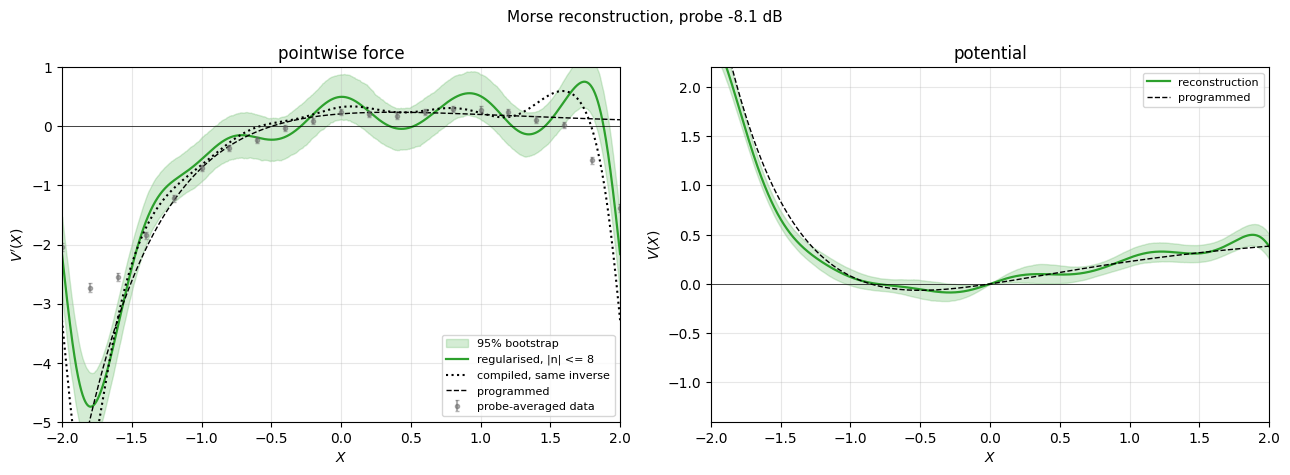

In [37]:
# =====================================================================
#  REGULARISED RECONSTRUCTION, bootstrap, Sim, and the hard-truncation cross-check
# =====================================================================
NMAX_REG = 8
PENALTY_P = 2

# Smoothing fixed by the noise-gain cap alone (no data values enter): eps such that
# the regularised inverse amplifies white noise as much in total as hard truncation
# at the cap, |n| <= N_THIS, which is the rule of the coherent-probe gates.  The same
# rule applied to a coherent probe is close to their |n| <= 2 cut; for this probe it
# differs because 1/H_6 is only just above the cap.
def _noise_power(eps):
    return sum((1 / inv_gain(n, SIGMA_X2) / ((1 / inv_gain(n, SIGMA_X2)) ** 2 + eps * n ** PENALTY_P)) ** 2
               for n in range(1, NMAX_REG + 1))
_target = sum(inv_gain(n, SIGMA_X2) ** 2 for n in range(1, N_THIS + 1))
from scipy.optimize import brentq as _brentq
EPS_NM = 10 ** _brentq(lambda le: _noise_power(10 ** le) - _target, -14, 2)
if EPS_NM < eps_floor(NMAX_REG, SIGMA_X2, PENALTY_P):
    raise ValueError("noise-matched eps lets a harmonic exceed the gain cap")
print(f"noise-matched smoothing: eps = {EPS_NM:.3e} (total noise gain of hard |n| <= {N_THIS})")
rec = deconvolve_gls(MU_REC, CH, XGRID, NMAX_REG, SIGMA_X2, eps_a=EPS_NM, eps_q=EPS_NM, p=PENALTY_P)
EPS_A, EPS_Q = rec["fit_a"]["eps"], rec["fit_q"]["eps"]
print(f"regularised inverse, |n| <= {NMAX_REG}: eps_q = {EPS_Q:.2e}, "
      f"effective parameters {rec['fit_q']['edf']:.1f} of {2 * NMAX_REG + 1}, "
      f"min a(X) = {rec['min_a']:.3f}")
print(f"\n{'n':>4}{'1/H_n':>9}{'fraction kept':>15}")
FILTER = {}
for n_ in range(1, NMAX_REG + 1):
    H = 1 / inv_gain(n_, SIGMA_X2)
    FILTER[n_] = H * H / (H * H + EPS_Q * n_ ** PENALTY_P)
    print(f"{n_:4d}{1 / H:9.2f}{FILTER[n_]:15.3f}")
N_HALF = max(n_ for n_, f in FILTER.items() if f >= 0.5)
print(f"harmonics kept at >= 50%: |n| <= {N_HALF}")

for _k, _f in (("w", rec["fit_a"]), ("q", rec["fit_q"])):
    print(f"{_k} channel GLS fit: chi2/dof = {_f['chi2']:.1f}/{_f['dof']:.1f}, p = {_f['p']:.3g}")

# ---- bootstrap: the raw-shot replicas through the same frozen inverse ----
boot_F = rec["apply"](CH["Ab"], CH["Qb"])
boot_V = np.array([integrate_force(XGRID, f) for f in boot_F])
Flo, Fhi = np.nanpercentile(boot_F, [2.5, 97.5], axis=0)
Vlo, Vhi = np.nanpercentile(boot_V, [2.5, 97.5], axis=0)
V = integrate_force(XGRID, rec["force"])
RECON_LABEL = f"regularised, |n| <= {NMAX_REG}"

# ---- Sim: the compiled circuit through the same inverse (noise-free) ---
F_perf, pg_perf = compiled_probe_response(MU_REC)
_i0 = CH["i0"]
F_RESOLVABLE = rec["apply"](pg_perf / pg_perf[_i0], pg_perf * F_perf / pg_perf[_i0])[0]
# ---- CROSS-CHECK: the rule used for the coherent-probe gates, hard truncation
#      at the gain cap (|n| <= N_THIS), same channels, covariance and bootstrap
rec_hard = deconvolve_gls(MU_REC, CH, XGRID, N_THIS, SIGMA_X2)
boot_hard = rec_hard["apply"](CH["Ab"], CH["Qb"])
Hlo, Hhi = np.nanpercentile(boot_hard, [2.5, 97.5], axis=0)
_mr = np.abs(XGRID) <= 1.8 + 1e-9
HARD = {"nmax": int(N_THIS),
        "w_chi2_dof_p": [rec_hard["fit_a"]["chi2"], rec_hard["fit_a"]["dof"], rec_hard["fit_a"]["p"]],
        "q_chi2_dof_p": [rec_hard["fit_q"]["chi2"], rec_hard["fit_q"]["dof"], rec_hard["fit_q"]["p"]],
        "min_w": rec_hard["min_a"],
        "band_halfwidth_median_|X|<=1.8": float(np.nanmedian((Hhi - Hlo)[_mr]) / 2),
        "band_halfwidth_median_|X|<=1.8_regularised": float(np.nanmedian((Fhi - Flo)[_mr]) / 2),
        "rms_rec_hard_minus_reg_|X|<=1.8": float(np.sqrt(np.nanmean((rec_hard["force"] - rec["force"])[_mr] ** 2)))}
print(f"\ncross-check, hard truncation |n| <= {N_THIS} (the coherent-gate rule):")
for _k, _v in HARD.items():
    print(f"  {_k:42s} {_v}")

NMAX_USED = int(NMAX_REG)
FILTER_USED = dict(FILTER)
EPS_USED = (float(EPS_A), float(EPS_Q))
print(f"\nreconstruction used from here on: {RECON_LABEL}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.fill_between(XGRID, Flo, Fhi, alpha=0.2, color="C2", label="95% bootstrap")
ax.plot(XGRID, rec["force"], lw=1.6, color="C2", label=RECON_LABEL)
ax.plot(XGRID, F_RESOLVABLE, "k:", lw=1.5, label="compiled, same inverse")
ax.plot(XGRID, morse_F(XGRID, MORSE_D, MORSE_A, MORSE_X0), "k--", lw=1, label="programmed")
ax.errorbar(sci.mu, sci.force, yerr=sci.force_se, fmt="o", ms=3, capsize=1.5,
            alpha=0.5, color="0.4", label="probe-averaged data")
ax.set_ylim(-5, 1.0); ax.set_ylabel(r"$V'(X)$"); ax.set_title("pointwise force")
ax = axes[1]
ax.fill_between(XGRID, Vlo, Vhi, alpha=0.2, color="C2")
ax.plot(XGRID, V, lw=1.6, color="C2", label="reconstruction")
_Vt = morse_V(XGRID, MORSE_D, MORSE_A, MORSE_X0)
ax.plot(XGRID, _Vt - np.interp(0.0, XGRID, _Vt), "k--", lw=1, label="programmed")
ax.set_ylim(-1.4, 2.2); ax.set_ylabel(r"$V(X)$"); ax.set_title("potential")
for a_ in axes:
    a_.axhline(0, lw=0.5, color="k")
    a_.set_xlabel("$X$"); a_.set_xlim(-2, 2); a_.legend(fontsize=8); a_.grid(alpha=0.3)
plt.suptitle(f"Morse reconstruction, probe {SQUEEZE_DB:+.1f} dB", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "02_reconstruction.png", dpi=200); plt.show()

pd.DataFrame({"X": XGRID, "force": rec["force"], "force_lo": Flo, "force_hi": Fhi,
              "V": V, "V_lo": Vlo, "V_hi": Vhi, "force_compiled_same_inverse": F_RESOLVABLE}
             ).to_csv(OUT / "02_reconstruction.csv", index=False)

## 5. What the band limit removes
(i) The r.m.s. residual over $|X|\le1.4$ of the compiled force rebuilt from harmonics $0,\dots,N$; (ii) the error budget over the same range: band limit (Sim minus compiled) and measurement (reconstruction minus Sim) (SM *Morse gate: reconstruction*).

In [38]:
# =====================================================================
#  WHAT THE BAND LIMIT REMOVES
#  (i)  r.m.s. over |X| <= W_HARM of the compiled force rebuilt from the
#       channel harmonics 0..N, against the exact compiled force;
#  (ii) the error budget over the same range: band limit (Sim - compiled)
#       and measurement (reconstruction - Sim).
# =====================================================================
W_HARM = 1.4
_m = np.abs(XGRID) <= W_HARM + 1e-9
_rms = lambda v: float(np.sqrt(np.nanmean(np.asarray(v)**2)))
RMS_FCOMP_HARM = _rms(F_COMP[_m])
_rows = []
for _N in range(1, M_QSP + 1):
    _FN = series(CQ, XGRID, 0.0, M=_N)/series(CA, XGRID, 0.0, M=_N)
    _rows.append({"N": _N, "eps_N": _rms(_FN[_m] - F_COMP[_m]),
                  "1/H_N this probe": inv_gain(_N, SIGMA_X2)})
harmonic_content = pd.DataFrame(_rows)
display(harmonic_content.style.format({"eps_N": "{:.3f}", "1/H_N this probe": "{:.3g}"}))
harmonic_content.to_csv(OUT / "harmonic_content.csv", index=False)
BUDGET_BANDLIMIT = _rms(F_RESOLVABLE[_m] - F_COMP[_m])
BUDGET_MEASUREMENT = _rms(rec["force"][_m] - F_RESOLVABLE[_m])
print(f"over |X| <= {W_HARM}: r.m.s. compiled force {RMS_FCOMP_HARM:.3f};  "
      f"band limit |Sim - compiled| {BUDGET_BANDLIMIT:.3f};  "
      f"measurement |reconstruction - Sim| {BUDGET_MEASUREMENT:.3f}")

,N,eps_N,1/H_N this probe
0,1,0.409,1.1
1,2,0.358,1.47
2,3,0.283,2.36
3,4,0.244,4.61
4,5,0.218,10.9
5,6,0.224,31.1
6,7,0.044,108
7,8,0.017,451
8,9,0.007,2.29e+03
9,10,0.003,1.4e+04


over |X| <= 1.4: r.m.s. compiled force 0.527;  band limit |Sim - compiled| 0.218;  measurement |reconstruction - Sim| 0.190


## 6. Morse gate
### 6.1 Window of the fit to the measured points
Largest $|X|\le W$ at which the compiled circuit, carried through the acceptance-weighted probe average with the bootstrap covariance, is consistent with the Morse form: median $p$ of the non-central $\chi^2$ $\ge$ `WINDOW_P_MIN` (SM *Analysis windows*).

In [39]:
# =====================================================================
#  ANALYSIS WINDOW: largest |X| <= W over which the COMPILED circuit's
#        probe response is consistent with the Morse form at the measured errors
# =====================================================================
from scipy.stats import ncx2 as _ncx2
P_MIN = WINDOW_P_MIN                           # consistency threshold (section 1)
WINDOWS = np.round(np.arange(0.8, 2.0001, 0.2), 6)


def morse_response(mu, D, a, x0):
    """The Morse force as this experiment would report it."""
    return probe_average(lambda t: morse_F(t, D, a, x0), mu, SIGMA_X2, a_compiled)


def fit_morse(mu, y, cov, p0=(MORSE_D, MORSE_A, MORSE_X0)):
    """GLS fit of the Morse response with the bootstrap covariance of the points;
    returns the whitened residuals."""
    p, c = curve_fit(morse_response, mu, y, p0=list(p0), sigma=cov,
                     absolute_sigma=True, maxfev=60000)
    r = np.linalg.solve(chol_whiten(cov), y - morse_response(mu, *p))
    return p, c, float(r @ r), len(mu) - 3, r


win_rows = []
for w_ in WINDOWS:
    mm = np.abs(sci.mu.values) <= w_ + 1e-9
    mu_w, se_w = sci.mu.values[mm], COV_F[np.ix_(mm, mm)]
    # compiled circuit, noise-free, weighted by the measured errors
    Fc_w = compiled_probe_response(mu_w)[0]
    pc, _, c2c, dc, rc = fit_morse(mu_w, Fc_w, se_w)
    # the data, for information
    pw, _, c2w, dw, _ = fit_morse(mu_w, sci.force.values[mm], se_w, p0=tuple(pc))
    # a perfect device measured at these errors: chi2 ~ noncentral(dof, lambda = c2c);
    # its typical (median) p-value is what the data test would return
    p_perfect = float(chi2_dist.sf(_ncx2.median(dc, max(c2c, 1e-12)), dc))
    win_rows.append({"window": w_, "n": int(mm.sum()),
                     "compiled: chi2 excess": c2c, "compiled: median p": p_perfect,
                     "compiled: max |whitened resid|": float(np.max(np.abs(rc))),
                     "data: chi2/dof": c2w / dw, "data: p": float(chi2_dist.sf(c2w, dw)),
                     "data: D": pw[0], "data: a": pw[1], "data: x0": pw[2]})
win_tbl = pd.DataFrame(win_rows)
display(win_tbl.round(4))
win_tbl.to_csv(OUT / "00_window_scan.csv", index=False)

_ok = (win_tbl["compiled: median p"] >= P_MIN).to_numpy()
_n_ok = int(np.argmin(_ok)) if not _ok.all() else len(_ok)   # nested: stop at first failure
if _n_ok == 0:
    raise ValueError(f"the compiled circuit is not Morse-like at the measured precision "
                     f"even at |X| <= {WINDOWS[0]}")
FIT_WINDOW = float(WINDOWS[_n_ok - 1])
_r = win_tbl.iloc[_n_ok - 1]
print(f"analysis window: |X| <= {FIT_WINDOW}  (largest window over which a perfect device, "
      f"measured at these errors, would typically be found consistent with the Morse form)")
if _n_ok < len(WINDOWS):
    print(f"  the compiled circuit departs from the Morse form from |X| <= {WINDOWS[_n_ok]} "
          f"(median p of a perfect device = {win_tbl['compiled: median p'].iloc[_n_ok]:.2g})")
print(f"  data at this window: chi2/dof = {_r['data: chi2/dof']:.2f}, p = {_r['data: p']:.3g}"
      + ("" if _r['data: p'] >= P_MIN else
         "   <- the data depart from the Morse form inside the window where the circuit does not"))

,window,n,compiled: chi2 excess,compiled: median p,compiled: max |whitened resid|,data: chi2/dof,data: p,data: D,data: a,data: x0
0,0.8,9,0.1415,0.4845,0.2805,1.0895,0.3658,0.9503,0.5719,-0.4309
1,1.0,11,0.2456,0.4765,0.2897,0.8767,0.5352,0.9268,0.5929,-0.4359
2,1.2,13,0.8257,0.4301,0.6693,0.9641,0.4726,0.7972,0.6684,-0.4703
3,1.4,15,1.3198,0.3989,0.6566,1.1568,0.3083,0.6931,0.7286,-0.5021
4,1.6,17,14.6604,0.0153,2.6636,1.7169,0.0454,0.6894,0.7086,-0.4753
5,1.8,19,400.4552,0.0000,14.2611,22.9829,0.0000,0.7520,0.5673,-0.2606
6,2.0,21,1659.1449,0.0000,22.0873,67.1221,0.0000,0.7839,0.3805,0.2298


analysis window: |X| <= 1.4  (largest window over which a perfect device, measured at these errors, would typically be found consistent with the Morse form)
  the compiled circuit departs from the Morse form from |X| <= 1.6 (median p of a perfect device = 0.015)
  data at this window: chi2/dof = 1.16, p = 0.308


### 6.2 Morse fit to the reconstruction
Window from Sim plus the bootstrap fluctuations, as for the cubic gate; the parameters are read against the same fit to Sim (SM *Morse gate: fit to the reconstruction*).

In [40]:
# =====================================================================
#  MORSE FORM IN RECONSTRUCTION SPACE: window from the band-limited compiled
#  circuit, then the fit to the reconstruction against the same reference
# =====================================================================
from scipy.optimize import least_squares as _lsq

P_MIN_B = WINDOW_P_MIN
WINDOWS_B = np.round(np.arange(0.8, 2.0001, 0.2), 6)
STRIDE_B = 5                                    # grid thinning for speed

_BFm = np.asarray(boot_F, float)


def _fit_recon_morse(y, xs, sd, p0):
    res = lambda p: (y - morse_F(xs, *p)) / sd
    r = _lsq(res, p0, bounds=([1e-3, 1e-3, -3.0], [20.0, 6.0, 3.0]), max_nfev=5000)
    J = r.jac                                    # already weighted by 1/sd
    return r.x, r.fun * sd, J


def _proj_remove(J):
    """Operator removing, in whitened units, the directions the fit can absorb."""
    Q, _ = np.linalg.qr(J)
    return lambda E: E - (E @ Q) @ Q.T


rows_b = []
for w_ in WINDOWS_B:
    m = np.where(np.abs(XGRID) <= w_ + 1e-9)[0][::STRIDE_B]
    ok = np.all(np.isfinite(_BFm[:, m]), axis=1)
    B = _BFm[ok][:, m]
    sd = B.std(axis=0, ddof=1)
    E = (B - B.mean(axis=0)) / sd                # whitened bootstrap fluctuations
    xs = XGRID[m]
    # data
    pd_, rd, Jd = _fit_recon_morse(rec["force"][m], xs, sd, (MORSE_D, MORSE_A, MORSE_X0))
    Rd = _proj_remove(Jd)
    T_null_d = np.sort(np.max(np.abs(Rd(E)), axis=1))
    T_d = float(np.max(np.abs(rd / sd)))
    p_d = float(1 - np.searchsorted(T_null_d, T_d, side="left") / len(T_null_d))
    dp = (np.linalg.pinv(Jd) @ E.T).T            # linearised parameter fluctuations
    se_d = dp.std(axis=0, ddof=1)
    # compiled circuit through the same inverse, and a perfect device at this noise
    pc, rc, Jc = _fit_recon_morse(F_RESOLVABLE[m], xs, sd, tuple(pd_))
    Rc = _proj_remove(Jc)
    T_null_c = np.sort(np.max(np.abs(Rc(E)), axis=1))
    T_pd = np.max(np.abs(rc / sd + Rc(E)), axis=1)
    p_pd = 1 - np.searchsorted(T_null_c, T_pd, side="left") / len(T_null_c)
    rows_b.append({"window": w_, "data: D": pd_[0], "data: a": pd_[1], "data: x0": pd_[2],
                   "se D": se_d[0], "se a": se_d[1], "se x0": se_d[2], "data: p": p_d,
                   "compiled via inverse: D": pc[0], "compiled via inverse: a": pc[1],
                   "compiled via inverse: x0": pc[2],
                   "perfect device: median p": float(np.median(p_pd))})
recon_morse_tbl = pd.DataFrame(rows_b)
display(recon_morse_tbl.round(4))
recon_morse_tbl.to_csv(OUT / "04b_recon_space_morse.csv", index=False)

_okb = (recon_morse_tbl["perfect device: median p"] >= P_MIN_B).to_numpy()
_nb = int(np.argmin(_okb)) if not _okb.all() else len(_okb)
if _nb == 0:
    W_RECON = np.nan
    print(f"the band-limited compiled circuit is not typically Morse-consistent even at "
          f"|X| <= {WINDOWS_B[0]}; no reconstruction-space Morse claim")
else:
    W_RECON = float(WINDOWS_B[_nb - 1])
    _rb = recon_morse_tbl.iloc[_nb - 1]
    P_RECON = np.array([_rb["data: D"], _rb["data: a"], _rb["data: x0"]])
    SE_RECON = np.array([_rb["se D"], _rb["se a"], _rb["se x0"]])
    P_RECON_REF = np.array([_rb["compiled via inverse: D"], _rb["compiled via inverse: a"],
                            _rb["compiled via inverse: x0"]])
    PV_RECON = float(_rb["data: p"])
    print(f"reconstruction-space window: |X| <= {W_RECON}  (largest window over which the "
          f"band-limited compiled circuit is typically Morse-consistent at this noise)")
    print(f"  data consistency with the Morse form there: p = {PV_RECON:.3g}")
    print(f"  {'':>28}{'D':>9}{'a':>9}{'x0':>9}")
    print(f"  {'reconstruction fit':>28}" + "".join(f"{v:9.3f}" for v in P_RECON))
    print(f"  {'+/-':>28}" + "".join(f"{v:9.3f}" for v in SE_RECON))
    print(f"  {'compiled through inverse':>28}" + "".join(f"{v:9.3f}" for v in P_RECON_REF))
    print(f"  {'programmed':>28}" + "".join(f"{v:9.3f}" for v in (MORSE_D, MORSE_A, MORSE_X0)))
    print("  pulls vs compiled through inverse: " + ", ".join(
        f"{n_} {(v - r) / s:+.1f}" for n_, v, r, s in zip(("D", "a", "x0"), P_RECON, P_RECON_REF, SE_RECON)))

,window,data: D,data: a,data: x0,se D,se a,se x0,data: p,compiled via inverse: D,compiled via inverse: a,compiled via inverse: x0,perfect device: median p
0,0.8,0.5474,0.7748,-0.4431,0.4261,0.4683,0.0816,0.4370,0.7654,0.7607,-0.5714,0.4935
1,1.0,2.0479,0.3587,-0.3782,2.2071,0.2308,0.0740,0.4475,0.7728,0.7662,-0.5655,0.4670
2,1.2,1.2356,0.4979,-0.4139,0.4553,0.1148,0.0588,0.5110,0.7627,0.7507,-0.5649,0.4545
3,1.4,0.7076,0.6637,-0.4708,0.1722,0.0995,0.0606,0.5605,0.8273,0.7024,-0.5498,0.4045
4,1.6,0.5103,0.8529,-0.5747,0.0719,0.0621,0.0467,0.3685,0.9212,0.7043,-0.5722,0.1155
5,1.8,0.5284,0.8932,-0.6227,0.0746,0.0550,0.0343,0.0965,0.7613,0.8324,-0.6586,0.0727
6,2.0,0.8496,0.6551,-0.4488,0.0742,0.0242,0.0318,0.0000,0.8705,0.7205,-0.5532,0.0000


reconstruction-space window: |X| <= 1.6  (largest window over which the band-limited compiled circuit is typically Morse-consistent at this noise)
  data consistency with the Morse form there: p = 0.369
                                      D        a       x0
            reconstruction fit    0.510    0.853   -0.575
                           +/-    0.072    0.062    0.047
      compiled through inverse    0.921    0.704   -0.572
                    programmed    0.600    0.800   -0.500
  pulls vs compiled through inverse: D -5.7, a +2.4, x0 -0.1


### 6.3 Fit to the measured points
The Morse force through the acceptance-weighted probe average, fitted to the measured points by GLS with their bootstrap covariance; the correlation of $D$ and $a$ and the curvature $2Da^2$ (SM *Morse gate: fit to the measured points*).

In [41]:
# =====================================================================
#  MORSE FIT to the measured points, through the measurement model
# =====================================================================
m_fit = np.abs(sci.mu.values) <= FIT_WINDOW + 1e-9
mu_f, F_f, se_f = sci.mu.values[m_fit], sci.force.values[m_fit], sci.force_se.values[m_fit]
C_f = COV_F[np.ix_(m_fit, m_fit)]                # bootstrap covariance of these points
L_f = chol_whiten(C_f)


popt, pcov, chi2, dof, resid = fit_morse(mu_f, F_f, C_f)
perr = np.sqrt(np.diag(pcov))
p_val = float(chi2_dist.sf(chi2, dof))
print(f"Morse through the measurement model, {m_fit.sum()} points, |X| <= {FIT_WINDOW}:")
print(f"  chi2/dof = {chi2:.1f}/{dof},  p = {p_val:.3f}")
for n_, v_, e_, t_ in zip(("D", "a", "x0"), popt, perr, (MORSE_D, MORSE_A, MORSE_X0)):
    print(f"  {n_:>2} = {v_:+.3f} +/- {e_:.3f}   (programmed {t_:+.2f})")

Morse through the measurement model, 15 points, |X| <= 1.4:
  chi2/dof = 13.9/12,  p = 0.308
   D = +0.693 +/- 0.073   (programmed +0.60)
   a = +0.729 +/- 0.034   (programmed +0.80)
  x0 = -0.502 +/- 0.032   (programmed -0.50)


In [42]:
# =====================================================================
#  FIT TO THE MEASURED POINTS: parameter correlation and curvature.
# =====================================================================
_sd = np.sqrt(np.diag(pcov))
CORR_DA = float(pcov[0, 1]/(_sd[0]*_sd[1]))
CURV = float(2*popt[0]*popt[1]**2)
_g = np.array([2*popt[1]**2, 4*popt[0]*popt[1], 0.0])
CURV_SE = float(np.sqrt(_g @ pcov @ _g))
print(f"corr(D, a) = {CORR_DA:+.2f};  curvature 2 D a^2 = {CURV:.3f} +/- {CURV_SE:.3f} "
      f"({100*CURV_SE/CURV:.1f}%)")

corr(D, a) = -0.82;  curvature 2 D a^2 = 0.736 +/- 0.045 (6.1%)


### 6.4 Alternative functional forms
Polynomial potentials of degree three to five through the same measurement model and covariance (SM *Morse gate: alternative forms*).

,model,n_param,chi2,dof,p
0,Morse,3,13.9,12,3.08e-01
1,cubic V,3,106.4,12,3.11e-17
2,quartic V,4,30.9,11,1.12e-03
3,quintic V,5,8.4,10,5.91e-01


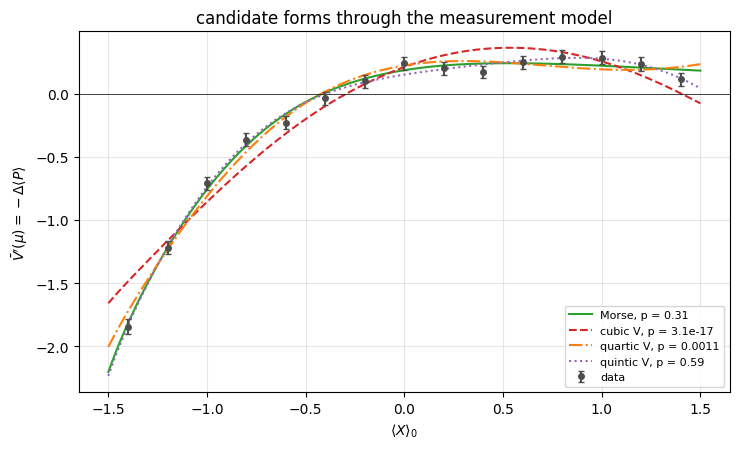

In [43]:
# =====================================================================
#  MODEL COMPARISON: Morse against polynomial potentials
# =====================================================================
def fit_poly(deg):
    A = np.vstack([probe_average(lambda t, k=k: t ** k, mu_f) for k in range(deg + 1)]).T
    Aw, yw = np.linalg.solve(L_f, A), np.linalg.solve(L_f, F_f)   # GLS, as the Morse fit
    c, *_ = np.linalg.lstsq(Aw, yw, rcond=None)
    r = yw - Aw @ c
    return {"chi2": float(r @ r), "npar": deg + 1, "coef": c,
            "curve": lambda x, c=c, d=deg: np.vstack(
                [probe_average(lambda t, k=k: t ** k, x) for k in range(d + 1)]).T @ c}


models = {"Morse": {"chi2": chi2, "npar": 3, "curve": lambda x: morse_response(x, *popt)}}
for deg, name in ((2, "cubic V"), (3, "quartic V"), (4, "quintic V")):
    models[name] = fit_poly(deg)
cmp = pd.DataFrame([{"model": k, "n_param": v["npar"], "chi2": v["chi2"],
                     "dof": len(mu_f) - v["npar"],
                     "p": float(chi2_dist.sf(v["chi2"], len(mu_f) - v["npar"]))}
                    for k, v in models.items()])
display(cmp.style.format({"chi2": "{:.1f}", "p": "{:.2e}"}))
cmp.to_csv(OUT / "05_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
xx = np.linspace(-FIT_WINDOW - 0.1, FIT_WINDOW + 0.1, 300)
ax.errorbar(mu_f, F_f, yerr=se_f, fmt="o", ms=4, capsize=2, color="0.3", label="data", zorder=5)
for (k, v), (c_, ls_) in zip(models.items(), (("C2", "-"), ("C3", "--"), ("C1", "-."), ("C4", ":"))):
    ax.plot(xx, v["curve"](xx), ls=ls_, color=c_, lw=1.5,
            label=f"{k}, p = {chi2_dist.sf(v['chi2'], len(mu_f) - v['npar']):.2g}")
ax.axhline(0, lw=0.5, color="k")
ax.set_xlabel(r"$\langle X\rangle_0$"); ax.set_ylabel(r"$\bar V'(\mu)=-\Delta\langle P\rangle$")
ax.set_title("candidate forms through the measurement model"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "05_model_comparison.png", dpi=200); plt.show()

### 6.5 The same fit to the compiled circuit
The compiled row of the parameter table.

In [44]:
# =====================================================================
#  THE SAME FIT TO THE COMPILED CIRCUIT
# =====================================================================
p_ref, _ = curve_fit(morse_response, mu_f, compiled_probe_response(mu_f)[0],
                     p0=list(popt), maxfev=60000)
d_ = popt - p_ref
chi2_compiled = float(d_ @ np.linalg.inv(pcov) @ d_)
pv_compiled = float(chi2_dist.sf(chi2_compiled, 3))
print(f"{'':>10}{'D':>9}{'a':>9}{'x0':>9}")
for lab_, p_ in (("programmed", (MORSE_D, MORSE_A, MORSE_X0)), ("compiled", p_ref), ("measured", popt)):
    print(f"{lab_:>10}{p_[0]:9.3f}{p_[1]:9.3f}{p_[2]:9.3f}")
print(f"{'+/-':>10}{perr[0]:9.3f}{perr[1]:9.3f}{perr[2]:9.3f}")
print(f"\nmeasured against compiled, full covariance (3 dof): chi2 = {chi2_compiled:.1f}, "
      f"p = {pv_compiled:.2g};  pulls " +
      ", ".join(f"{n_} {v_ / s_:+.1f}" for n_, v_, s_ in zip(("D", "a", "x0"), d_, perr)))
pd.DataFrame({"param": ["D", "a", "x0"], "measured": popt, "se": perr, "compiled": p_ref,
              "programmed": [MORSE_D, MORSE_A, MORSE_X0]}).to_csv(OUT / "06_morse_parameters.csv", index=False)

                  D        a       x0
programmed    0.600    0.800   -0.500
  compiled    0.856    0.715   -0.560
  measured    0.693    0.729   -0.502
       +/-    0.073    0.034    0.032

measured against compiled, full covariance (3 dof): chi2 = 11.9, p = 0.0078;  pulls D -2.2, a +0.4, x0 +1.8


### 6.6 Probe footprint
Probe weight beyond the Fourier interval at the window edge, and the compiled circuit averaged over a coherent probe there.

In [45]:
# =====================================================================
#  PROBE FOOTPRINT: probe weight beyond the Fourier interval
# =====================================================================
from scipy.stats import norm as _norm


def weight_outside(mu, s2):
    s = np.sqrt(s2)
    return float(_norm.sf((L / 2 - mu) / s) + _norm.cdf((-L / 2 - mu) / s))


foot = pd.DataFrame({"|mu|": [1.0, 1.2, 1.4, 1.6],
                     "outside, this probe": [weight_outside(m_, SIGMA_X2) for m_ in (1.0, 1.2, 1.4, 1.6)],
                     "outside, coherent": [weight_outside(m_, S2_COH) for m_ in (1.0, 1.2, 1.4, 1.6)]})
display(foot.style.format({"outside, this probe": "{:.2%}", "outside, coherent": "{:.1%}"}))
OUT_THIS, OUT_COH = weight_outside(FIT_WINDOW, SIGMA_X2), weight_outside(FIT_WINDOW, S2_COH)
print(f"at |mu| = {FIT_WINDOW}: {100 * OUT_THIS:.1f}% of this probe lies beyond |X| = 2, "
      f"{100 * OUT_COH:.0f}% of a coherent one")

,|mu|,"outside, this probe","outside, coherent"
0,1.000000,0.02%,7.9%
1,1.200000,0.20%,12.9%
2,1.400000,1.55%,19.8%
3,1.600000,7.53%,28.6%


at |mu| = 1.4: 1.6% of this probe lies beyond |X| = 2, 20% of a coherent one


In [46]:
# ---- the compiled circuit averaged over a coherent probe at the window edge
_mu_e = np.array([-FIT_WINDOW, FIT_WINDOW])
COH_EDGE = compiled_probe_response(_mu_e, S2_COH)[0]
print("compiled circuit through a coherent probe at mu = "
      + ", ".join(f"{m:+.1f}: {f:+.3f}" for m, f in zip(_mu_e, COH_EDGE))
      + "   (Morse force there: "
      + ", ".join(f"{morse_F(m, MORSE_D, MORSE_A, MORSE_X0):+.3f}" for m in _mu_e) + ")")

compiled circuit through a coherent probe at mu = -1.4: -1.098, +1.4: -0.242   (Morse force there: -2.080, +0.164)


### 6.7 Probe compression and bandwidth
For each $n_{\max}$: the compression that keeps $1/H_n\le G$, $2n_{\max}+3$ probe centres, and the noise-free reconstruction error of the compiled circuit (SM *Probe compression and bandwidth*).

In [47]:
# =====================================================================
#  PROBE COMPRESSION AND BANDWIDTH (SM section of that name)
#  For each n_max: the compression S(n_max) that keeps 1/H_n <= G for
#  |n| <= n_max, 2 n_max + 3 equally spaced probe centres, and the
#  reconstruction error of the compiled circuit, noise free, with hard
#  truncation at n_max.
# =====================================================================
_G = MAX_INVERSE_GAIN
_mfull = np.abs(XGRID) <= 2.0
_rms_ref = float(np.sqrt(np.mean(F_COMP[_mfull]**2)))
_rows = []
for _nm in range(2, M_QSP + 1):
    _k = 2*np.pi*_nm/L
    _S = 10*np.log10(_k**2/(4*np.log(_G)))
    _s2 = 0.5 if _S <= 0 else 0.5*10**(-_S/10)
    _mu_c = np.linspace(-2.0, 2.0, 2*_nm + 3)
    _A = fourier_design(_mu_c, _nm, _s2, L)
    _ca = np.linalg.lstsq(_A, series(CA, _mu_c, _s2), rcond=None)[0]
    _cq = np.linalg.lstsq(_A, series(CQ, _mu_c, _s2), rcond=None)[0]
    _B = fourier_basis(XGRID, _nm, L)
    _a, _q = _B @ _ca, _B @ _cq
    _F = np.where(_a > 1e-3, _q/np.where(_a > 1e-3, _a, 1.0), np.nan)
    _e = float(np.sqrt(np.nanmean((_F - F_COMP)[_mfull]**2)))
    _rows.append({"n_max": _nm, "S_dB": max(_S, 0.0), "sigma_X2": _s2,
                  "probes": 2*_nm + 3, "eps": _e, "eps/rms": _e/_rms_ref})
bandwidth_cost = pd.DataFrame(_rows)
display(bandwidth_cost.round(4))
bandwidth_cost.to_csv(OUT / "bandwidth_cost.csv", index=False)
print(f"r.m.s. of the compiled force over |X| <= 2: {_rms_ref:.3f}")
_nz_a = [n for n in range(1, M_QSP + 3) if abs(CA[n]) > 1e-12]
_nz_q = [n for n in range(1, M_QSP + 3) if abs(CQ[n]) > 1e-12]
print(f"highest nonzero harmonic: w channel {max(_nz_a)}, q channel {max(_nz_q)}")

,n_max,S_dB,sigma_X2,probes,eps,eps/rms
0,2,0.0000,0.5000,7,1.4795,0.6454
1,3,2.6792,0.2698,9,1.2413,0.5415
2,4,5.1780,0.1518,11,1.0238,0.4466
3,5,7.1162,0.0971,13,0.8170,0.3564
4,6,8.6998,0.0675,15,0.6192,0.2701
5,7,10.0387,0.0496,17,0.3885,0.1695
6,8,11.1986,0.0379,19,0.2335,0.1019
7,9,12.2216,0.0300,21,0.1247,0.0544
8,10,13.1368,0.0243,23,0.0591,0.0258
9,11,13.9646,0.0201,25,0.0236,0.0103


r.m.s. of the compiled force over |X| <= 2: 2.292
highest nonzero harmonic: w channel 13, q channel 12


## 7. Acceptance and post-selection
Measured $p_g$ against the compiled acceptance averaged over the same probe, and the pointwise $A_M^2$, over both analysis windows (SM *Acceptance and post-selection*).

In [48]:
# =====================================================================
#  ACCEPTANCE AS QUOTED: window means, hardware shortfall, where it trails off
# =====================================================================
TRAIL_BELOW = 0.65            # report probe centres whose measured p_g falls below this

_mu_all = sci.mu.values
_pg_all = sci.pg.values
_pgse_all = sci.pg_se.values
_apr_all = compiled_probe_response(_mu_all)[1]           # compiled, probe-averaged
_apt_all = a_compiled(_mu_all)                           # compiled, pointwise A_M^2

acc_points = pd.DataFrame({"mu": _mu_all, "measured p_g": _pg_all, "se": _pgse_all,
                           "compiled, probe-averaged": _apr_all, "compiled, pointwise A_M^2": _apt_all})
acc_points["measured / compiled"] = acc_points["measured p_g"] / acc_points["compiled, probe-averaged"]
acc_points = acc_points.sort_values("mu").reset_index(drop=True)

_wins = [(FIT_WINDOW, "forward fit")]
if "W_RECON" in globals() and np.isfinite(W_RECON):
    _wins.append((W_RECON, "reconstruction fit"))

acc_quote = {}
for W, lab in _wins:
    sel = acc_points[np.abs(acc_points["mu"]) <= W + 1e-9]
    xg = np.linspace(-W, W, 2001)
    trail = sel[sel["measured p_g"] < TRAIL_BELOW]
    acc_quote[W] = dict(
        n=len(sel),
        meas_mean=float(sel["measured p_g"].mean()),
        meas_min=float(sel["measured p_g"].min()), meas_max=float(sel["measured p_g"].max()),
        mu_at_min=float(sel.loc[sel["measured p_g"].idxmin(), "mu"]),
        probe_mean=float(sel["compiled, probe-averaged"].mean()),
        point_mean=float(a_compiled(xg).mean()),
        ratio_mean=float(sel["measured / compiled"].mean()),
        trail_mu=trail["mu"].to_numpy(), trail_pg=trail["measured p_g"].to_numpy())
    q = acc_quote[W]
    print(f"|X| <= {W} ({lab}), {q['n']} probe centres")
    print(f"  measured p_g: mean {q['meas_mean']:.3f}  (range {q['meas_min']:.3f}-{q['meas_max']:.3f}, "
          f"lowest at mu = {q['mu_at_min']:+.1f})")
    print(f"  compiled acceptance: probe-averaged mean {q['probe_mean']:.3f}, pointwise A_M^2 mean {q['point_mean']:.3f}")
    print(f"  measured / compiled (probe-averaged), mean: {q['ratio_mean']:.3f}   <- hardware")
    if len(trail):
        print(f"  trails off below {TRAIL_BELOW}: " +
              ", ".join(f"mu = {m:+.1f} ({p:.2f})" for m, p in zip(q["trail_mu"], q["trail_pg"])))
    else:
        print(f"  never below {TRAIL_BELOW}")
    print()

_W = max(acc_quote)
_core = acc_points[np.abs(acc_points["mu"]) <= _W + 1e-9]
with pd.option_context("display.float_format", "{:.3f}".format):
    display(_core)
acc_points.to_csv(OUT / "acceptance_points.csv", index=False)

|X| <= 1.4 (forward fit), 15 probe centres
  measured p_g: mean 0.853  (range 0.773-0.875, lowest at mu = -1.4)
  compiled acceptance: probe-averaged mean 0.944, pointwise A_M^2 mean 0.959
  measured / compiled (probe-averaged), mean: 0.904   <- hardware
  never below 0.65

|X| <= 1.6 (reconstruction fit), 17 probe centres
  measured p_g: mean 0.838  (range 0.687-0.875, lowest at mu = -1.6)
  compiled acceptance: probe-averaged mean 0.924, pointwise A_M^2 mean 0.952
  measured / compiled (probe-averaged), mean: 0.907   <- hardware
  never below 0.65



,mu,measured p_g,se,"compiled, probe-averaged","compiled, pointwise A_M^2",measured / compiled
2,-1.600,0.687,0.001,0.707,0.828,0.971
3,-1.400,0.773,0.001,0.835,0.913,0.926
4,-1.200,0.835,0.001,0.917,0.941,0.910
5,-1.000,0.864,0.001,0.952,0.994,0.908
6,-0.800,0.870,0.001,0.958,0.969,0.908
7,-0.600,0.875,0.001,0.955,0.918,0.916
8,-0.400,0.870,0.001,0.952,0.981,0.915
9,-0.200,0.863,0.001,0.947,0.960,0.912
10,0.000,0.862,0.001,0.944,0.893,0.913
11,0.200,0.862,0.001,0.950,0.963,0.908


## 8. Agreement with Sim
Over each window: the fraction in which Sim lies inside the 95% bootstrap band of the
reconstruction (the shaded region of the figures), and the r.m.s. difference between the measured
probe-averaged forces and the compiled response, relative to the r.m.s. bootstrap error of the
measured forces and to the r.m.s. compiled response (SM *Agreement with Sim*).

In [49]:
# =====================================================================
#  §8 --- AGREEMENT WITH SIM, over each window W:
#    coverage     fraction of |X| <= W (uniform grid) in which Sim lies inside
#                 the 95% bootstrap band of the reconstruction, i.e. the
#                 shaded region of the figures
#    point error  r.m.s. of (measured - compiled) probe-averaged force over the
#                 probe centres in |X| <= W, relative to the r.m.s. of the
#                 compiled response there; no reconstruction enters
#    point noise  r.m.s. bootstrap error of those measured forces, in the same
#                 units
#    ratio        point error / point noise: near 1 means the measured forces
#                 differ from the compiled response by the noise alone
# =====================================================================
_mu_p = sci.mu.to_numpy(float)
_F_p = sci.force.to_numpy(float)
_C_p = np.asarray(COV_F, float)
_se_p = np.sqrt(np.clip(np.diag(_C_p), 0, None))
_F_c = np.asarray(compiled_probe_response(_mu_p)[0], float)

_X = np.asarray(XGRID, float)
_F_sim = np.asarray(F_RESOLVABLE, float)                 # Sim
_lo, _hi = np.asarray(Flo, float), np.asarray(Fhi, float)

_wins = {}
if np.isfinite(W_RECON):
    _wins[f"reconstruction-fit window |X| <= {float(W_RECON):g}"] = float(W_RECON)
_wins[f"direct-fit window |X| <= {float(FIT_WINDOW):g}"] = float(FIT_WINDOW)
_wins["full range |X| <= 2"] = L/2 + 1e-6

def _rms(v):
    v = np.asarray(v, float)
    return float(np.sqrt(np.mean(v**2)))


def agreement_with_sim(W):
    gx = (np.abs(_X) <= W + 1e-9) & np.isfinite(_F_sim) & np.isfinite(_lo) & np.isfinite(_hi)
    inside = (_F_sim[gx] >= _lo[gx]) & (_F_sim[gx] <= _hi[gx])
    gp = np.abs(_mu_p) <= W + 1e-9
    err, noise = _rms(_F_p[gp] - _F_c[gp]), _rms(_se_p[gp])
    return {"W": min(float(W), 2.0), "coverage": float(inside.mean()), "probes": int(gp.sum()),
            "point_error": err/_rms(_F_c[gp]), "point_noise": noise/_rms(_F_c[gp]),
            "ratio": err/noise}


_rows = []
for _name, _W in _wins.items():
    _r = agreement_with_sim(_W)
    _rows.append({"range": _name, **_r})
    PAPER[f"agreement.{_name.split(' |')[0].replace(' ', '_')}.W_coverage_ratio_pointerr_pointnoise"] = [
        _r["W"], _r["coverage"], _r["ratio"], _r["point_error"], _r["point_noise"]]
AGREEMENT = pd.DataFrame(_rows)
AGREEMENT.to_csv(OUT / "agreement_with_sim.csv", index=False)
print("Sim against the data (point error and noise relative to the r.m.s. compiled response):")
display(AGREEMENT.round(4))

Sim against the data (point error and noise relative to the r.m.s. compiled response):


,range,W,coverage,probes,point_error,point_noise,ratio
0,reconstruction-fit window |X| <= 1.6,1.6,0.9274,17,0.0746,0.0612,1.2194
1,direct-fit window |X| <= 1.4,1.4,0.9679,15,0.1053,0.0800,1.3157
2,full range |X| <= 2,2.0,0.8132,21,0.1117,0.0493,2.2681


## 9. Values quoted in the paper

In [50]:
# =====================================================================
#  VALUES QUOTED IN THE PAPER -- Morse gate
# =====================================================================
P = PAPER
_r3 = lambda v: [float(x) for x in np.asarray(v, float).ravel()]
# ---- acquisition, calibration, probe --------------------------------------
P["acq.probe"] = "position-compressed"
P["acq.scans"] = 1
P["acq.probe_centres"] = int(len(sci))
P["acq.reps_per_cf_point"] = sorted({int(v) for v in sci.reps})
P["acq.cf_points_per_cut"] = sorted({int(v) for v in sci.n_cf})
P["acq.binary_outcomes"] = int((sci.reps*sci.n_cf).sum())
P["acq.vacuum_calibrations"] = 2
P["cal.Lambda"] = [cal_before["den"], cal_after["den"]]
P["cal.Lambda_se"] = [cal_before["se"], cal_after["se"]]
P["cal.crosshair_sigma_X2"] = [cal_before["sigma_X2_crosshair"], cal_after["sigma_X2_crosshair"]]
P["cal.cf_fit_degree"] = int(CF_POLY_ORDER)
P["probe.sigma_X2"] = float(SIGMA_X2)
P["probe.compression_dB"] = float(SQUEEZE_DB)
P["probe.sigma_P2"] = float(VAR_P_MEAS)
P["probe.variance_product"] = float(SIGMA_X2*VAR_P_MEAS)
# ---- bandwidth and compiled circuit -------------------------------------------
P["bandwidth.n_coherent"] = int(N_COH)
P["bandwidth.n_compressed"] = int(N_THIS)
P["bandwidth.inverse_gain_compressed_n1..8"] = [float(inv_gain(n, SIGMA_X2)) for n in range(1, 9)]
P["bandwidth.dB_for_all_M_harmonics"] = float(DB_ALL)
P["circuit.M"] = int(M_QSP)
# ---- reconstruction --------------------------------------------------------------
P["recon.method"] = "regularised"
P["recon.nmax"] = int(NMAX_USED)
P["recon.eps_w_eps_q"] = [float(EPS_USED[0]), float(EPS_USED[1])]
P["recon.kept_fraction_n1..8"] = [float(FILTER_USED[n]) for n in range(1, NMAX_REG + 1)]
P["recon.min_w"] = float(rec["min_a"])
P["recon.bootstrap_replicas"] = int(len(boot_F))
P["errors.method"] = "raw-shot bootstrap, GLS"
P["recon.eps_rule"] = "noise-matched to hard truncation at the gain cap"
P["recon.input_probe_centres"] = int(REC_SEL.sum())
P["recon.w_channel.chi2_dof_p"] = [float(rec["fit_a"]["chi2"]), float(rec["fit_a"]["dof"]), float(rec["fit_a"]["p"])]
P["recon.q_channel.chi2_dof_p"] = [float(rec["fit_q"]["chi2"]), float(rec["fit_q"]["dof"]), float(rec["fit_q"]["p"])]
for _k, _v in HARD.items():
    P[f"crosscheck.hard_truncation.{_k}"] = _v
P["errors.mean_corr_between_probe_forces"] = CORR_F_MEAN
P["acceptance.definition"] = "P(gate g | probe g)" if ACCEPT_CONDITIONAL else "P(both g)"
P["acceptance.joint_P_both_g_mean_min_max"] = [float(sci.pg_joint.mean()), float(sci.pg_joint.min()), float(sci.pg_joint.max())]
P["acceptance.preparation_selection_mean_min_max"] = [float(sci.prep_pass.mean()), float(sci.prep_pass.min()), float(sci.prep_pass.max())]
P["recon.resolved_modes_w_q"] = [int(CH["ZA"].shape[0]), int(CH["ZQ"].shape[0])]
# ---- what the band limit removes --------------------------------------------------
P["budget.W"] = W_HARM
P["budget.rms_compiled_force"] = RMS_FCOMP_HARM
P["budget.bandlimit_Sim_minus_compiled"] = BUDGET_BANDLIMIT
P["budget.measurement_rec_minus_Sim"] = BUDGET_MEASUREMENT
P["harmonics.eps_N_N1..M"] = harmonic_content["eps_N"].tolist()
# ---- windows ------------------------------------------------------------------------------
P["window.threshold"] = WINDOW_P_MIN
P["window.direct_fit.W"] = FIT_WINDOW
P["window.direct_fit.scan.W"] = win_tbl["window"].tolist()
P["window.direct_fit.scan.Sim_median_p"] = win_tbl["compiled: median p"].tolist()
P["window.direct_fit.scan.data_p"] = win_tbl["data: p"].tolist()
P["window.recon_fit.W"] = W_RECON
for _, _r in recon_morse_tbl.iterrows():
    P[f"recon_fit.W{_r['window']:g}.p_D_a_x0_seD_sea_sex0"] = _r3(
        [_r["data: p"], _r["data: D"], _r["data: a"], _r["data: x0"], _r["se D"], _r["se a"], _r["se x0"]])
    P[f"recon_fit.W{_r['window']:g}.Sim_D_a_x0_medianp"] = _r3(
        [_r["compiled via inverse: D"], _r["compiled via inverse: a"],
         _r["compiled via inverse: x0"], _r["perfect device: median p"]])
# ---- direct fit -------------------------------------------------------------------------------
P["direct_fit.n_points"] = int(len(mu_f))
P["direct_fit.chi2_dof_p"] = [float(chi2), int(dof), float(p_val)]
P["direct_fit.D_a_x0"] = _r3(popt)
P["direct_fit.se"] = _r3(perr)
P["direct_fit.compiled_D_a_x0"] = _r3(p_ref)
P["direct_fit.vs_compiled.chi2_p"] = [float(chi2_compiled), float(pv_compiled)]
P["direct_fit.vs_compiled.pulls"] = _r3((popt - p_ref)/perr)
P["direct_fit.corr_D_a"] = CORR_DA
P["direct_fit.curvature_2Da2_se"] = [CURV, CURV_SE]
for _r in cmp.itertuples():
    P[f"alternatives.{_r.model}.npar_chi2_p"] = [int(_r.n_param), float(_r.chi2), float(_r.p)]
P["footprint.outside_fraction_compressed_coherent"] = [OUT_THIS, OUT_COH]
P["footprint.compiled_coherent_at_-W_+W"] = _r3(COH_EDGE)
# ---- probe compression and bandwidth --------------------------------------------------------
P["bandwidth_cost.n_max"] = bandwidth_cost["n_max"].tolist()
P["bandwidth_cost.S_dB"] = bandwidth_cost["S_dB"].tolist()
P["bandwidth_cost.sigma_X2"] = bandwidth_cost["sigma_X2"].tolist()
P["bandwidth_cost.eps"] = bandwidth_cost["eps"].tolist()
P["bandwidth_cost.eps_rel"] = bandwidth_cost["eps/rms"].tolist()
# ---- acceptance -------------------------------------------------------------------------------
for _W, _q in sorted(acc_quote.items()):
    P[f"acceptance.|X|<={_W:g}.A_M^2_pointwise_mean"] = _q["point_mean"]
    P[f"acceptance.|X|<={_W:g}.<A_M^2>_mu_mean"] = _q["probe_mean"]
    P[f"acceptance.|X|<={_W:g}.p_g_mean_min_max"] = [_q["meas_mean"], _q["meas_min"], _q["meas_max"]]
    P[f"acceptance.|X|<={_W:g}.measured/compiled_mean"] = _q["ratio_mean"]
    P[f"acceptance.|X|<={_W:g}.p_g_below_{TRAIL_BELOW}"] = {f"{m:+.1f}": float(p) for m, p in
                                                           zip(_q["trail_mu"], _q["trail_pg"])}
    _xg = np.linspace(-_W, _W, 2001)
    P[f"acceptance.|X|<={_W:g}.A_M^2_pointwise_min_max"] = [float(a_compiled(_xg).min()),
                                                            float(a_compiled(_xg).max())]

In [51]:
# =====================================================================
#  Print the collected values between fixed markers (read by
#  extract_outputs.py) and write them to OUT/paper_values.json.
# =====================================================================
def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [_plain(x) for x in list(np.asarray(v, dtype=object).ravel())] \
            if isinstance(v, np.ndarray) else [_plain(x) for x in v]
    if isinstance(v, (np.bool_, bool)):
        return bool(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return float(v)
    return v


def _fmt(v):
    v = _plain(v)
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, int):
        return str(v)
    if isinstance(v, float):
        if not np.isfinite(v):
            return "nan"
        return f"{v:.4g}" if (v == 0 or 1e-3 <= abs(v) < 1e5) else f"{v:.3e}"
    if isinstance(v, list):
        return "[" + ", ".join(_fmt(x) for x in v) + "]"
    if isinstance(v, dict):
        return "{" + ", ".join(f"{k}: {_fmt(x)}" for k, x in v.items()) + "}"
    return str(v)


import json
print(f"===== PAPER VALUES: {GATE} =====")
for _k, _v in PAPER.items():
    print(f"{_k} = {_fmt(_v)}")
print(f"===== END PAPER VALUES: {GATE} =====")
(OUT / "paper_values.json").write_text(json.dumps(_plain(PAPER), indent=1, default=str))

===== PAPER VALUES: Morse =====
agreement.reconstruction-fit_window.W_coverage_ratio_pointerr_pointnoise = [1.6, 0.9274, 1.219, 0.07465, 0.06122]
agreement.direct-fit_window.W_coverage_ratio_pointerr_pointnoise = [1.4, 0.9679, 1.316, 0.1053, 0.08002]
agreement.full_range.W_coverage_ratio_pointerr_pointnoise = [2, 0.8132, 2.268, 0.1117, 0.04926]
acq.probe = position-compressed
acq.scans = 1
acq.probe_centres = 21
acq.reps_per_cf_point = [20000]
acq.cf_points_per_cut = [21]
acq.binary_outcomes = 8820000
acq.vacuum_calibrations = 2
cal.Lambda = [1.919, 1.928]
cal.Lambda_se = [0.02421, 0.04022]
cal.crosshair_sigma_X2 = [0.5597, 0.5773]
cal.cf_fit_degree = 5
probe.sigma_X2 = 0.0774
probe.compression_dB = -8.102
probe.sigma_P2 = 5.154
probe.variance_product = 0.3989
bandwidth.n_coherent = 2
bandwidth.n_compressed = 5
bandwidth.inverse_gain_compressed_n1..8 = [1.1, 1.465, 2.362, 4.608, 10.88, 31.11, 107.7, 450.9]
bandwidth.dB_for_all_M_harmonics = 15.42
circuit.M = 13
recon.method = regularis

9923

## 10. Figures
Main-text Fig. 4: (a) the reconstructed potential and (b) the reconstructed force, with Sim, the
target and the coherent-probe simulation (Sim Coh.), shaded outside the window of the Morse fit to
the reconstruction; (c) the harmonics needed by each target force. Supplementary Morse figure: the
measured probe-averaged forces with the Morse fit to the measured points, shaded outside that fit's
window. Bare (no text) SVG panels for assembly, labelled versions, and the plotted curves as CSV are
written to the output folder.

In [52]:
# =====================================================================
#  §10 --- FIGURE SETTINGS: what is drawn, colours, axes and layout.
#  Everything about how the figures look is set here.
# =====================================================================
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

# ---- what is drawn -------------------------------------------------------------
SHOW_COHERENT_SIM = True      # the compiled circuit through a coherent probe, on (a), (b) and the supplement
COHERENT_VAR_X = 0.5          # vacuum width
# (a), (b): Sim Coh., the coherent probe's simulation, as if the experiment had used
#   coherent probes: the compiled circuit's acceptance a and force channel aV' averaged
#   over a coherent probe at the measured probe centres, each fitted with harmonics
#   |n| <= 2 and deconvolved (divided by H_n); their ratio is the force and its
#   integral the potential.  Noise-free.
SHOW_RECON_BAND = True        # 95% bootstrap band of the compressed reconstruction
SHOW_COMPILED_RECON = True    # (a), (b): the compiled circuit through the compressed probe's inverse
SHOW_COMPILED_FORWARD = True  # supplement: the compiled circuit averaged over the compressed probe
SHOW_DIRECT_FIT = True        # supplement: the Morse form fitted to the measured points, probe-averaged
DIRECT_FIT_SPAN = "window"    # "window": drawn over the fit window only; "full": over the whole axis

# ---- palette and line styles ---------------------------------------------------
ORANGE_DARK, ORANGE_MID, ORANGE_LIGHT = "#AE4500", "#FB6023", "#FFA366"
PURPLE_DARK, PURPLE_MID, PURPLE_LIGHT = "#2A0080", "#7534F8", "#AE88F9"
COHERENT_COLOR = "#FFB000"                                       # IBM yellow: coherent-probe simulation
LS_COHERENT = "-."                                               # its line style, on every panel
# target (solid), reconstruction / data (dashed, band, points), compiled circuit (dotted)
POT_COLOR = {"target": PURPLE_DARK, "rec": PURPLE_MID, "comp": PURPLE_LIGHT}     # (a)
FORCE_COLOR = {"target": ORANGE_DARK, "rec": ORANGE_MID, "comp": ORANGE_LIGHT}   # (b), supplement
FIT_COLOR, LS_FIT = ORANGE_MID, "--"                             # supplement: the direct Morse fit
PROBES = ("coherent", "compressed")          # the data are compressed only
LS_TARGET, LS_RECON, LS_COMPILED = "-", "--", ":"
LW, LW_GUIDE = 1.0, 0.5
MARKER_SIZE = 2.5
BAND_ALPHA = 0.20
WINDOW_COLOR, WINDOW_ALPHA = "0.4", 0.10
# thin dotted line at each edge of a shaded region, as in the cubic and double-well figures
BOUNDARY_KW = dict(color="0.55", ls=":", lw=0.6, zorder=1)

# ---- axes ------------------------------------------------------------------------
XLIM = (-2.0, 2.0)
VREF = None                   # potentials referenced here; None: the target minimum
YLIM_POT, YTICK_POT = (-0.4, 3.0), 1.0
YLIM_FORCE, YTICK_FORCE = (-6, 1.0), 2.0
YLIM_FWD, YTICK_FWD = (-3.0, 0.5), 1.0
GAIN_CAP = 20.0               # deconvolution noise-gain cap, 1/H_n

# ---- layout, in cm -----------------------------------------------------------------
GRID_W_CM = 7.6               # main figure: total width (8.6 = a full column)
GRID_H_CM = 3               # main figure: height of (a) and (b)
GRID_PADS = {"bare": dict(l=0.25, r=0.15, b=0.25, t=0.15, gx=0.40, gy=0.35),
             "labelled": dict(l=1.00, r=0.20, b=0.80, t=0.45, gx=1.05, gy=1.15)}
# supplementary single panel
SUPP_AX_W_CM, SUPP_AX_H_CM = 7.2, 4.6       # plotting area (labelled total ~8.5 cm: one column)
SUPP_PADS = {"bare": dict(l=0.25, r=0.15, b=0.25, t=0.15),
             "labelled": dict(l=1.00, r=0.25, b=0.85, t=0.20)}
SUPP_LEGEND_NCOL = 1                        # the _legend export: legend columns underneath the axes
SUPP_LEGEND_ROW_CM = 0.30                   # height per legend row (the room grows with the entries)
SUPP_LEGEND_FONTSIZE = 5.5
SUPP_LEGEND_PARAMS = True                   # the fitted D, a, x0 in the fit's legend entry

RC = {"font.size": 7, "font.family": "sans-serif",
      "font.sans-serif": ["Calibri", "Calibri", "Calibri"],
      "figure.facecolor": "none", "axes.facecolor": "none",
      "savefig.transparent": True, "svg.fonttype": "none",
      "axes.edgecolor": "#000000", "axes.labelcolor": "#000000",
      "xtick.color": "#000000", "ytick.color": "#000000", "text.color": "#000000",
      "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
      "xtick.minor.width": 0.8, "ytick.minor.width": 0.8,
      "xtick.major.size": 2.5, "ytick.major.size": 2.5,
      "xtick.minor.size": 1.5, "ytick.minor.size": 1.5}
CM = 1 / 2.54
print(f"figures are written to {OUT}")

figures are written to results_morse


In [53]:
# =====================================================================
#  DATA: every plotted curve, from the analysis above
# =====================================================================
def interp_nan(x_new, x, y):
    """Linear interpolation that keeps NaN gaps, and NaN outside the data's range."""
    x = np.asarray(x, float); y = np.asarray(y, float); ok = np.isfinite(y)
    out = np.interp(x_new, x[ok], y[ok]) if ok.sum() >= 2 else np.full(len(x_new), np.nan)
    out[np.interp(x_new, x, (~ok).astype(float)) > 0] = np.nan
    out[(x_new < x.min() - 1e-9) | (x_new > x.max() + 1e-9)] = np.nan
    return out


L = 4.0                                   # the gate's period


def interp_periodic(x_new, x, y):
    """A curve given over one period of the compiled gate, continued periodically."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    keep = np.isfinite(y) & (x < x.min() + L - 1e-9)
    return np.interp(x_new, x[keep], y[keep], period=L)


def integrate(x, F, zero_at):
    """Cumulative trapezoid of a force, zero at zero_at; NaN-safe."""
    F = np.asarray(F, float); ok = np.isfinite(F)
    out = np.full(x.shape, np.nan)
    if ok.sum() < 2:
        return out
    xs, fs = x[ok], F[ok]
    v = np.concatenate([[0.0], np.cumsum(0.5 * (fs[1:] + fs[:-1]) * np.diff(xs))])
    out[ok] = v - np.interp(zero_at, xs, v)
    return out


# ---- the curves from sections 2-6, sampled exactly as they are plotted ----------
_stride = max(1, int(round((len(XGRID) - 1) / 800)))       # thinned grid for the bootstrap
ds = {"x": np.asarray(XGRID, float), "F_rec": np.asarray(rec["force"], float),
      "F_lo": np.asarray(Flo, float), "F_hi": np.asarray(Fhi, float),
      "F_comp_est": np.asarray(F_RESOLVABLE, float),
      "x_boot": np.asarray(XGRID, float)[::_stride],
      "boot_F": np.asarray(boot_F, float)[:, ::_stride].astype(np.float32),
      "mu_data": sci.mu.to_numpy(float), "F_data": sci.force.to_numpy(float),
      "F_data_se": sci.force_se.to_numpy(float)}
T_D, T_A, T_X0 = MORSE_D, MORSE_A, MORSE_X0
VREF_USED = T_X0 if VREF is None else float(VREF)
RECON_WINDOW = float(W_RECON)        # window of the fit to the reconstruction, shaded in (a), (b)
# FIT_WINDOW (section 6.1) is the window of the fit to the measured points, shaded in the
# supplementary figure


def F_target(x):
    e = np.exp(-T_A * (np.asarray(x, float) - T_X0))
    return 2 * T_D * T_A * e * (1 - e)


def V_target(x):
    return T_D * (1 - np.exp(-T_A * (np.asarray(x, float) - T_X0))) ** 2


def compiled_force(x):
    """The compiled circuit's own force V'_M(X), no probe averaging; periodic."""
    return series(CQ, x) / series(CA, x)


def compiled_response(x, s2):
    """The compiled circuit's acceptance-weighted average <aV'>/<a> over a probe of
    variance s2 centred at x (section 3)."""
    return compiled_probe_response(x, s2)[0]


# ---- (a), (b): reconstructions on one grid -------------------------------------------
X = np.linspace(XLIM[0], XLIM[1], 2001)
POT = {"target": V_target(X) - V_target(VREF_USED)}
FORCE = {"target": F_target(X)}
# compressed probe: the measured reconstruction and its compiled reference
F = interp_nan(X, ds["x"], ds["F_rec"])
Fc = interp_periodic(X, ds["x"], ds["F_comp_est"])        # Sim; the compiled circuit repeats
xb = np.asarray(ds["x_boot"], float)
Vb = np.array([integrate(xb, f, VREF_USED) for f in np.asarray(ds["boot_F"], float)])
vlo, vhi = np.nanpercentile(Vb, [2.5, 97.5], axis=0)
POT.update({"rec": integrate(X, F, VREF_USED), "comp": integrate(X, Fc, VREF_USED),
            "lo": interp_nan(X, xb, vlo), "hi": interp_nan(X, xb, vhi)})
FORCE.update({"rec": F, "comp": Fc,
              "lo": interp_nan(X, ds["x"], ds["F_lo"]), "hi": interp_nan(X, ds["x"], ds["F_hi"])})

VAR_X = {"compressed": float(SIGMA_X2), "coherent": float(COHERENT_VAR_X)}


def H(n, s2):
    """Probe-average attenuation of harmonic n, exp(-s2 k_n^2 / 2)."""
    return np.exp(-0.5 * s2 * (2 * np.pi * np.asarray(n, float) / L) ** 2)


N_KEEP = {p: int(np.floor(np.sqrt(2 * np.log(GAIN_CAP) / VAR_X[p]) * L / (2 * np.pi))) for p in PROBES}

def _deconvolve_truncated(mu, y, s2, nmax, x):
    """Fit y(mu) with harmonics |n| <= nmax by least squares, divide each by H_n
    (undo the probe average), and evaluate at x: the coherent analysis's
    truncated deconvolution, on noise-free data."""
    def design(t):
        cols = [np.ones_like(t)]
        for n in range(1, nmax + 1):
            k = 2 * np.pi * n / L
            cols += [np.cos(k * t), np.sin(k * t)]
        return np.column_stack(cols)
    coef, *_ = np.linalg.lstsq(design(np.asarray(mu, float)), y, rcond=None)
    gain = np.r_[1.0, np.repeat([1 / H(n, s2) for n in range(1, nmax + 1)], 2)]
    return design(np.asarray(x, float)) @ (coef * gain)


# Sim Coh.: the compiled circuit through coherent probes at the measured centres
_mu = np.asarray(ds["mu_data"], float)
_s2, _N = VAR_X["coherent"], N_KEEP["coherent"]
F_coh = (_deconvolve_truncated(_mu, series(CQ, _mu, _s2), _s2, _N, X)
         / _deconvolve_truncated(_mu, series(CA, _mu, _s2), _s2, _N, X))
FORCE["coh_sim"] = F_coh
POT["coh_sim"] = integrate(X, F_coh, VREF_USED)
FWD_COH = compiled_response(X, VAR_X["coherent"])         # supplement: what a coherent probe measures
FWD_COMP = compiled_response(X, VAR_X["compressed"])      # supplement: what the compressed probe measures

# ---- supplement: the measured points, compressed probe ------------------------------
PTS = {"mu": np.asarray(ds["mu_data"], float), "F": np.asarray(ds["F_data"], float),
       "se": np.asarray(ds["F_data_se"], float)}

# ---- supplement: the Morse fit to the measured points (section 6.3), drawn through the
#      same acceptance-weighted probe average, probe_average of section 3 ------------------
_mt = np.linspace(-1.8, 1.8, 37)          # same forward model as the compiled response
assert np.allclose(probe_average(compiled_force, _mt, VAR_X["compressed"]),
                   compiled_response(_mt, VAR_X["compressed"]), atol=1e-8), "acceptance weighting"
FIT_P = np.asarray(popt, float)
FIT_SE = np.asarray(perr, float)
FWD_FIT = probe_average(lambda t: morse_F(t, *FIT_P), X, VAR_X["compressed"])
if DIRECT_FIT_SPAN == "window":
    FWD_FIT[np.abs(X) > FIT_WINDOW + 1e-9] = np.nan
elif DIRECT_FIT_SPAN != "full":
    raise ValueError(f"DIRECT_FIT_SPAN must be 'window' or 'full', not {DIRECT_FIT_SPAN!r}")

print(f"Morse target D = {T_D}, a = {T_A}, x0 = {T_X0};  potentials referenced to X = {VREF_USED:+.2f}")
print(f"windows: reconstruction |X| <= {RECON_WINDOW}, forward propagation |X| <= {FIT_WINDOW}")
print(f"direct Morse fit over |X| <= {FIT_WINDOW:g}: D = {FIT_P[0]:.3f} +/- {FIT_SE[0]:.3f}, "
      f"a = {FIT_P[1]:.3f} +/- {FIT_SE[1]:.3f}, x0 = {FIT_P[2]:+.3f} +/- {FIT_SE[2]:.3f};  "
      f"2Da^2 = {2 * FIT_P[0] * FIT_P[1] ** 2:.3f}")
for p in PROBES:
    print(f"  {p:>10}: var_X = {VAR_X[p]:.4f}, restores |n| <= {N_KEEP[p]}")
print(f"compressed reconstruction: {RECON_LABEL};  coherent probe simulated "
      f"(|n| <= {N_KEEP['coherent']})")
print("\ndata ranges, for setting the axis limits (reconstructions and data only):")
_r = lambda q, keys: np.concatenate([q[k] for k in keys])
_ks = ["rec", "lo", "hi", "comp", "coh_sim"]
print(f"  potential {np.nanmin(_r(POT, _ks)):+.2f} to {np.nanmax(_r(POT, _ks)):+.2f}   (limits {YLIM_POT})")
print(f"  force     {np.nanmin(_r(FORCE, _ks)):+.2f} to {np.nanmax(_r(FORCE, _ks)):+.2f}   (limits {YLIM_FORCE})")
_v = np.r_[PTS["F"], FWD_COH[np.abs(X) <= 2]]
print(f"  forward   {_v.min():+.2f} to {_v.max():+.2f}   (limits {YLIM_FWD})")

Morse target D = 0.6, a = 0.8, x0 = -0.5;  potentials referenced to X = -0.50
windows: reconstruction |X| <= 1.6, forward propagation |X| <= 1.4
direct Morse fit over |X| <= 1.4: D = 0.693 +/- 0.073, a = 0.729 +/- 0.034, x0 = -0.502 +/- 0.032;  2Da^2 = 0.736
    coherent: var_X = 0.5000, restores |n| <= 2
  compressed: var_X = 0.0774, restores |n| <= 5
compressed reconstruction: regularised, |n| <= 8;  coherent probe simulated (|n| <= 2)

data ranges, for setting the axis limits (reconstructions and data only):
  potential -0.11 to +2.96   (limits (-0.4, 3.0))
  force     -5.91 to +1.22   (limits (-6, 1.0))
  forward   -2.73 to +0.29   (limits (-3.0, 0.5))


In [54]:
# =====================================================================
#  DRAWING: one function per panel; `text` False hides tick numbers and
#  axis labels (the bare export)
# =====================================================================
def _labels(ax, text, xlabel=None, ylabel=None):
    if not text:
        ax.tick_params(labelbottom=False, labelleft=False)
        return
    if xlabel: ax.set_xlabel(xlabel, labelpad=1.5)
    if ylabel: ax.set_ylabel(ylabel, labelpad=1.5)
    ax.tick_params(pad=1.5)


def _clip(x, y, ylim, log=False):
    """Cut a curve at the axes' y-limits: points outside become NaN, and the exact
    crossing is inserted, so nothing is drawn beyond the plot (in any SVG editor,
    which may ignore clip paths)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    lo, hi = (np.log10(ylim[0]), np.log10(ylim[1])) if log else ylim
    with np.errstate(divide="ignore", invalid="ignore"):
        t = np.log10(y) if log else y.copy()
    t[~np.isfinite(t)] = np.nan
    xs, ts = [], []
    for i in range(len(x)):
        if i > 0 and np.isfinite(t[i - 1]) and np.isfinite(t[i]):
            for b in (lo, hi):                       # crossings between i-1 and i
                if (t[i - 1] - b) * (t[i] - b) < 0:
                    f = (b - t[i - 1]) / (t[i] - t[i - 1])
                    xs.append(x[i - 1] + f * (x[i] - x[i - 1])); ts.append(b)
                    if not (lo <= t[i] <= hi):       # leaving: break the line
                        xs.append(np.nan); ts.append(np.nan)
        inside = np.isfinite(t[i]) and lo <= t[i] <= hi
        xs.append(x[i]); ts.append(t[i] if inside else np.nan)
    xs, ts = np.array(xs), np.array(ts)
    return xs, (10.0 ** ts if log else ts)


def _plot(ax, x, y, *args, ylim, log=False, **kw):
    ax.plot(*_clip(x, y, ylim, log), *args, **kw)


def _shade_outside(ax, w):
    """Grey outside the analysis window |X| <= w, white inside, with a thin dotted
    line at each edge of the window."""
    for a, b in ((XLIM[0], -w), (w, XLIM[1])):
        if b > a:
            ax.axvspan(a, b, color=WINDOW_COLOR, alpha=WINDOW_ALPHA, lw=0, zorder=0)
    for edge in (-w, w):
        if XLIM[0] < edge < XLIM[1]:
            ax.axvline(edge, **BOUNDARY_KW)


def _draw_recon(ax, curves, rc, ylim):
    """Shared by (a) and (b): window, the coherent-probe simulation, the compressed
    band, Sim and the reconstruction, then the target."""
    ax.axhline(0, color="#000000", lw=LW_GUIDE, zorder=0)
    _shade_outside(ax, RECON_WINDOW)
    if SHOW_COHERENT_SIM:
        _plot(ax, X, curves["coh_sim"], LS_COHERENT, ylim=ylim, color=COHERENT_COLOR, lw=LW, zorder=1.9)
    if SHOW_RECON_BAND:
        ax.fill_between(X, np.clip(curves["lo"], *ylim), np.clip(curves["hi"], *ylim),
                        color=rc["rec"], alpha=BAND_ALPHA, lw=0, zorder=0.8)
    if SHOW_COMPILED_RECON:
        _plot(ax, X, curves["comp"], LS_COMPILED, ylim=ylim, color=rc["comp"], lw=LW, zorder=2)
    _plot(ax, X, curves["rec"], LS_RECON, ylim=ylim, color=rc["rec"], lw=LW, zorder=3)
    _plot(ax, X, curves["target"], LS_TARGET, ylim=ylim, color=rc["target"], lw=LW, zorder=4)
    ax.set_xlim(XLIM)
    ax.xaxis.set_major_locator(MultipleLocator(1))


def draw_potential(ax, text):
    _draw_recon(ax, POT, POT_COLOR, YLIM_POT)
    ax.set_ylim(YLIM_POT); ax.yaxis.set_major_locator(MultipleLocator(YTICK_POT))
    _labels(ax, text, r"$X$", r"$V(X)$")


def draw_force(ax, text):
    _draw_recon(ax, FORCE, FORCE_COLOR, YLIM_FORCE)
    ax.set_ylim(YLIM_FORCE); ax.yaxis.set_major_locator(MultipleLocator(YTICK_FORCE))
    _labels(ax, text, r"$X$", r"$V'(X)$")


def draw_forward(ax, text):
    """Supplement: measured probe-averaged force, the direct Morse fit, the target
    and the compiled circuit through both probes."""
    ax.axhline(0, color="#000000", lw=LW_GUIDE, zorder=0)
    _shade_outside(ax, FIT_WINDOW)
    if SHOW_COHERENT_SIM:
        _plot(ax, X, FWD_COH, LS_COHERENT, ylim=YLIM_FWD, color=COHERENT_COLOR, lw=LW, zorder=3)
    if SHOW_COMPILED_FORWARD:
        _plot(ax, X, FWD_COMP, LS_COMPILED, ylim=YLIM_FWD, color=FORCE_COLOR["comp"], lw=LW, zorder=3.5)
    _plot(ax, X, F_target(X), LS_TARGET, ylim=YLIM_FWD, color=FORCE_COLOR["target"], lw=LW, zorder=4)
    if SHOW_DIRECT_FIT:
        _plot(ax, X, FWD_FIT, LS_FIT, ylim=YLIM_FWD, color=FIT_COLOR, lw=LW, zorder=5)
    c = FORCE_COLOR["rec"]
    inside = (PTS["F"] >= YLIM_FWD[0]) & (PTS["F"] <= YLIM_FWD[1]) & (PTS["mu"] >= XLIM[0]) & (PTS["mu"] <= XLIM[1])
    if (~inside).any():
        print(f"supplement: {(~inside).sum()} measured point(s) outside the axes, not drawn")
    ax.errorbar(PTS["mu"][inside], PTS["F"][inside], yerr=PTS["se"][inside], fmt="o", ms=MARKER_SIZE, mfc=c,
                mec=c, mew=0.3, ecolor=c, elinewidth=LW_GUIDE, capsize=0, zorder=10)
    ax.set_xlim(XLIM); ax.set_ylim(YLIM_FWD)
    ax.xaxis.set_major_locator(MultipleLocator(1)); ax.yaxis.set_major_locator(MultipleLocator(YTICK_FWD))
    _labels(ax, text, r"$\langle\hat X\rangle_0$", r"$\langle V'\rangle$")


def _coh_label():
    return rf"compiled, coherent probes, $|n|\leq{N_KEEP['coherent']}$ deconvolution"


def legend_groups():
    """Legend entries for the main figure's (a) and (b), for its preview."""
    win = [Patch(color=WINDOW_COLOR, alpha=WINDOW_ALPHA + 0.1, label="outside analysis window")]
    coh = ([Line2D([], [], color=COHERENT_COLOR, lw=LW, ls=LS_COHERENT, label=_coh_label())]
           if SHOW_COHERENT_SIM else [])

    def recon(rc):
        h = [Line2D([], [], color=rc["target"], lw=LW, label="programmed target")]
        h += [Line2D([], [], color=rc["rec"], lw=LW, ls=LS_RECON, label="reconstructed, compressed probe")]
        if SHOW_COMPILED_RECON:
            h += [Line2D([], [], color=rc["comp"], lw=LW, ls=LS_COMPILED,
                         label="compiled, same inverse, compressed probe")]
        if SHOW_RECON_BAND:
            h += [Patch(color=rc["rec"], alpha=BAND_ALPHA + 0.1, label="95% bootstrap band")]
        return h + coh + win

    return [("(a)", recon(POT_COLOR)), ("(b)", recon(FORCE_COLOR))]


def legend_forward():
    """Legend entries for the supplementary panel."""
    fc = FORCE_COLOR
    h = [Line2D([], [], ls="", marker="o", ms=MARKER_SIZE, color=fc["rec"], mec=fc["rec"],
                mew=0.3, label="measured, compressed probe")]
    if SHOW_DIRECT_FIT:
        lab = rf"Morse fit, $|\langle\hat X\rangle_0|\leq{FIT_WINDOW:g}$"
        if SUPP_LEGEND_PARAMS:
            lab += (rf": $D={FIT_P[0]:.2f}({100 * FIT_SE[0]:.0f})$, $a={FIT_P[1]:.2f}({100 * FIT_SE[1]:.0f})$, "
                    rf"$x_0={FIT_P[2]:.2f}({100 * FIT_SE[2]:.0f})$")
        h += [Line2D([], [], color=FIT_COLOR, lw=LW, ls=LS_FIT, label=lab)]
    h += [Line2D([], [], color=fc["target"], lw=LW, label="programmed target")]
    if SHOW_COMPILED_FORWARD:
        h += [Line2D([], [], color=fc["comp"], lw=LW, ls=LS_COMPILED, label="compiled, compressed-probe average")]
    if SHOW_COHERENT_SIM:
        h += [Line2D([], [], color=COHERENT_COLOR, lw=LW, ls=LS_COHERENT, label="compiled, coherent-probe average")]
    h += [Patch(color=WINDOW_COLOR, alpha=WINDOW_ALPHA + 0.1, label="outside fit window")]
    return h


print("drawing functions defined")

drawing functions defined


### 10.1 Supplementary figure: the Morse fit to the measured points

- the measured probe-averaged force of the compressed probe (mid orange points, bootstrap errors);
- the Morse form fitted to those points over the fit window (`fit_window` in the export),
  probe-averaged exactly as the analysis does it: the acceptance-weighted average
  $\langle a\,V'_{\rm Morse}\rangle/\langle a\rangle$ over the measured probe width, with the fitted
  $(D, a, x_0)$ from the export (dashed, mid orange; `SHOW_DIRECT_FIT`, `DIRECT_FIT_SPAN`);
- the programmed target (solid, dark orange), and the compiled circuit averaged over the compressed
  probe (dotted, light orange) and over a coherent probe (dash-dotted, yellow), i.e. what noise-free
  compressed and coherent probes measure;
- grey outside the fit window.

Outputs, all with the same plotting area (`SUPP_AX_W_CM` × `SUPP_AX_H_CM`): `supp_forward_bare.svg`
(no text, for assembly), `supp_forward_labelled.svg/.pdf/.png` (ticks and axis labels) and
`supp_forward_legend.svg/.pdf/.png` (labelled, with the legend underneath); the plotted curves
and points as `curves_forward.csv`, `points_forward.csv` and `morse_fit.csv`.

saved supp_forward_bare (7.60 x 5.00 cm; plotting area 7.2 x 4.6 cm)
saved supp_forward_labelled (8.45 x 5.65 cm; plotting area 7.2 x 4.6 cm)
saved supp_forward_legend (8.45 x 7.70 cm; plotting area 7.2 x 4.6 cm)


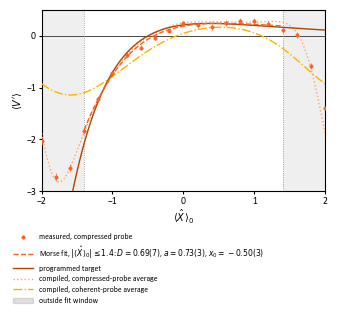

curves_forward.csv, points_forward.csv and morse_fit.csv in results_morse


In [55]:
# =====================================================================
#  SUPPLEMENTARY: ONE PANEL --- measured probe-averaged force and the
#  direct Morse fit, with the target and the compiled circuit
# =====================================================================
def build_supp(mode):
    """mode: "bare" (no text), "labelled", or "legend" (labelled + legend underneath)."""
    text = mode != "bare"
    P = SUPP_PADS["bare" if mode == "bare" else "labelled"]
    handles = legend_forward()
    rows = -(-len(handles) // SUPP_LEGEND_NCOL)
    leg = 0.25 + rows * SUPP_LEGEND_ROW_CM if mode == "legend" else 0.0
    W = P["l"] + SUPP_AX_W_CM + P["r"]
    Hh = leg + P["b"] + SUPP_AX_H_CM + P["t"]
    fig = plt.figure(figsize=(W * CM, Hh * CM))
    ax = fig.add_axes([P["l"] / W, (leg + P["b"]) / Hh, SUPP_AX_W_CM / W, SUPP_AX_H_CM / Hh])
    draw_forward(ax, text)
    if mode == "legend":
        fig.legend(handles=handles, loc="upper left", ncol=SUPP_LEGEND_NCOL, frameon=False,
                   fontsize=SUPP_LEGEND_FONTSIZE, handlelength=2.6, columnspacing=1.2,
                   bbox_to_anchor=(0.1 / W, (leg - 0.05) / Hh))
    return fig


with plt.rc_context(RC):
    for mode in ("bare", "labelled", "legend"):
        fig = build_supp(mode)
        name = f"supp_forward_{mode}"
        fig.savefig(OUT / f"{name}.svg", format="svg", transparent=True)
        if mode != "bare":
            fig.savefig(OUT / f"{name}.pdf", transparent=True)
            fig.savefig(OUT / f"{name}.png", dpi=300)
        print(f"saved {name} ({fig.get_figwidth() / CM:.2f} x {fig.get_figheight() / CM:.2f} cm; "
              f"plotting area {SUPP_AX_W_CM} x {SUPP_AX_H_CM} cm)")
        if mode == "legend":
            plt.show()
        plt.close(fig)

# every plotted curve and point, as CSV
pd.DataFrame({"X": X, "target": F_target(X), "morse_fit_probe_averaged": FWD_FIT,
              "compiled_compressed": FWD_COMP, "compiled_coherent": FWD_COH}).to_csv(
    OUT / "curves_forward.csv", index=False)
pd.DataFrame({"mu": PTS["mu"], "force": PTS["F"], "se": PTS["se"],
              "in_fit_window": np.abs(PTS["mu"]) <= FIT_WINDOW + 1e-9}).to_csv(OUT / "points_forward.csv", index=False)
pd.DataFrame({"param": ["D", "a", "x0"], "value": FIT_P, "se": FIT_SE}).to_csv(OUT / "morse_fit.csv", index=False)
print(f"curves_forward.csv, points_forward.csv and morse_fit.csv in {OUT}")

### 10.2 Main-text figure: (a) potential | (b) force, over (c) harmonics needed

(c) shows why the probe matters for each gate. Each target force (cubic, symmetric double well, Morse) is drawn over one period of the Fourier interval and half a period of its periodic copies on each side (grey). Each point is coloured by the smallest number of harmonics $N$ for which the force's Fourier series truncated to $|n|\le N$ stays within `HARM_TOL_FRAC` (10%) of the force's range there; the error is taken as its largest value within half a wavelength of the first omitted harmonic, so the zeros of the truncation ripple do not count. Black vertical segments are jumps where the periodic copies meet; open circles mark the double well's stationary points.

The colour bar converts $N$ to the probe squeezing that keeps $|n|\le N$ under the noise-gain cap (`GAIN_CAP`), $\sigma_X^2\le 2\ln(\mathrm{cap})/k_N^2$, i.e. at this experiment's noise level; the marker shows the compressed probe used here.

Outputs: `main_bare.svg`, `main_labelled.svg/.pdf/.png`, `main_preview.png` (with legends), and `panel_c_bare.svg` / `panel_c_labelled.svg`.

In [56]:
# =====================================================================
#  (c) HARMONICS NEEDED --- settings and data
# =====================================================================
HARM_TOL_FRAC = 0.10          # tolerance: fraction of each force's range over one period
HARM_NMAX = 40                # largest truncation tried; beyond it -> top colour
HARM_XLIM = (-4.0, 4.0)       # one period plus half a period of copies on each side
HARM_GATES = [                # (label, force V'(X), y-limits, stationary points to mark)
    ("cubic",       lambda x: 1.8 * x ** 2,          (-1.0, 8.5), []),
    ("double well", lambda x: 0.4 * x ** 3 - 0.6 * x, (-2.6, 2.6), []),
    ("Morse",       F_target,                         (-8.2, 2.0), []),
]
# colour bins in N: what coherent probes keep | what this compressed probe keeps |
# the compiled order | HARM_NMAX | beyond
HARM_EDGES = [N_KEEP["coherent"], N_KEEP["compressed"], M_QSP, HARM_NMAX]
HARM_COLORS = ["#FFB000", "#FB6023", "#B0306A", "#3B1F7A", "#000000"]
HARM_LW = 1.8

_hx = np.linspace(HARM_XLIM[0], HARM_XLIM[1], 4001)
_hdx = _hx[1] - _hx[0]
_hwrap = lambda x: (np.asarray(x) + L / 2) % L - L / 2
_NQ = 2048
_xs = -L / 2 + (np.arange(_NQ) + 0.5) / _NQ * L       # midpoints: no sample on the seam


def _fourier(f):
    """Coefficients of f on one period, referenced to X = -L/2."""
    return np.fft.fft(f(_xs)) / _NQ * np.exp(-1j * np.pi * np.arange(_NQ) / _NQ)


def _partial(c, x, N):
    xx = np.asarray(x, float) + L / 2
    out = np.full(xx.shape, c[0].real)
    for n in range(1, N + 1):
        k = 2 * np.pi * n / L
        out += 2 * (c[n].real * np.cos(k * xx) - c[n].imag * np.sin(k * xx))
    return out


def harmonics_needed(f):
    """Smallest N from which the |n|<=N series stays within tolerance for every larger N
    up to HARM_NMAX (HARM_NMAX + 1 if never)."""
    from scipy.ndimage import maximum_filter1d
    c = _fourier(f)
    exact = f(_hwrap(_hx))
    tol = HARM_TOL_FRAC * (f(_xs).max() - f(_xs).min())
    bad = np.array([maximum_filter1d(np.abs(exact - _partial(c, _hx, N)),
                                     size=max(3, int(L / (2 * (N + 1)) / _hdx))) > tol
                    for N in range(1, HARM_NMAX + 1)])
    any_bad = bad.any(axis=0)
    last_bad = HARM_NMAX - 1 - np.argmax(bad[::-1], axis=0)    # index of the last failing N
    return np.where(any_bad, last_bad + 2, 1)                   # N = index + 1, so next N = index + 2


def squeezing_db(N):
    """dB below vacuum that keeps harmonics |n|<=N under the noise-gain cap."""
    k = 2 * np.pi * N / L
    return 10 * np.log10(0.5 / (2 * np.log(GAIN_CAP) / k ** 2))


HARM = [(lab, f, yl, st, harmonics_needed(f)) for lab, f, yl, st in HARM_GATES]
DB_PROBE = 10 * np.log10(0.5 / VAR_X["compressed"])
print(f"(c): tolerance {100 * HARM_TOL_FRAC:.0f}% of range; bins N <= {HARM_EDGES}")
print("    squeezing for each bin edge: " + ", ".join(f"N<={N}: {squeezing_db(N):.1f} dB" for N in HARM_EDGES))
print(f"    this probe: {DB_PROBE:.1f} dB, keeps |n| <= {N_KEEP['compressed']}")
for lab, f, yl, st, req in HARM:
    inner = np.abs(_hx) <= L / 2
    for N, name in ((N_KEEP["coherent"], "coherent"), (N_KEEP["compressed"], "compressed")):
        badx = _hx[inner][req[inner] > N]
        print(f"    {lab:>11}, {name:>10} probes fall short at "
              + ("none" if len(badx) == 0 else f"X < {badx[badx < 0].max():+.2f}" if (badx < 0).any() else "")
              + (f", X > {badx[badx > 0].min():+.2f}" if (badx > 0).any() else ""))

(c): tolerance 10% of range; bins N <= [2, 5, 13, 40]
    squeezing for each bin edge: N<=2: -0.8 dB, N<=5: 7.1 dB, N<=13: 15.4 dB, N<=40: 25.2 dB
    this probe: 8.1 dB, keeps |n| <= 5
          cubic,   coherent probes fall short at X < -1.60, X > +1.60
          cubic, compressed probes fall short at none
    double well,   coherent probes fall short at X < -1.33, X > +1.33
    double well, compressed probes fall short at X < -1.67, X > +1.68
          Morse,   coherent probes fall short at X < -0.90, X > +1.28
          Morse, compressed probes fall short at X < -1.68, X > +1.67


In [57]:
# =====================================================================
#  (c) HARMONICS NEEDED --- drawing
# =====================================================================
from matplotlib.ticker import MaxNLocator
import matplotlib.transforms as mtransforms
import matplotlib.patches as mpatches

_hb = [0.5] + [e + 0.5 for e in HARM_EDGES] + [HARM_NMAX + 1.5]


def draw_harmonics_row(ax, lab, f, yl, stat, req, text, show_x):
    for s in (HARM_XLIM[0], L / 2):                       # grey over the periodic copies
        ax.axvspan(s, s + (L / 2 if s < 0 else HARM_XLIM[1] - L / 2), color=WINDOW_COLOR,
                   alpha=WINDOW_ALPHA, lw=0, zorder=0)
    for edge in (-L / 2, L / 2):                           # edges of the Fourier interval
        ax.axvline(edge, **BOUNDARY_KW)
    ax.axhline(0, color="#000000", lw=LW_GUIDE, zorder=0)
    y = f(_hwrap(_hx)).astype(float)
    y[np.abs(np.abs(_hwrap(_hx)) - L / 2) < 1.5 * _hdx] = np.nan  # break at the seams
    b = np.digitize(req, _hb[1:-1])
    run = np.r_[0, np.cumsum((np.diff(b) != 0) | np.isnan(y[1:]) | np.isnan(y[:-1]))]
    for r in np.unique(run):                                # one line per colour run
        idx = np.where(run == r)[0]
        if idx[-1] + 1 < len(_hx) and np.isfinite(y[idx[-1] + 1]):
            idx = np.r_[idx, idx[-1] + 1]
        if np.isfinite(y[idx]).sum() >= 2:
            ax.plot(_hx[idx], y[idx], "-", color=HARM_COLORS[b[idx[0]]], lw=HARM_LW,
                    solid_capstyle="butt", zorder=4)
    lo, hi = f(-L / 2), f(L / 2)
    if abs(hi - lo) > 1e-9:                                 # the jumps
        for s in (-L / 2, L / 2):
            ax.plot([s, s], [hi, lo], "-", color=HARM_COLORS[-1], lw=HARM_LW,
                    solid_capstyle="butt", zorder=5)
    for z in stat:
        for sh in (-L, 0, L):
            if HARM_XLIM[0] + 0.05 < z + sh < HARM_XLIM[1] - 0.05:
                ax.plot(z + sh, 0, "o", ms=MARKER_SIZE + 0.5, mfc="white", mec="#000000",
                        mew=0.6, zorder=7)
    ax.set_xlim(HARM_XLIM); ax.set_ylim(yl)
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MaxNLocator(3))            # same ticks bare and labelled
    if text:
        ax.set_ylabel(lab.replace(" ", "\n") + "\n" + r"$V'(X)$", labelpad=1.5, fontsize=6,
                      linespacing=1.0)
        ax.tick_params(pad=1.5)
        if show_x:
            ax.set_xlabel(r"$X$", labelpad=1.5)
        else:
            ax.tick_params(labelbottom=False)
    else:
        ax.tick_params(labelbottom=False, labelleft=False)


HARM_CBAR_GAP = 0.06      # white gap between neighbouring colours, as a fraction of one bin


def draw_harmonics_colorbar(fig, cax, text):
    """Discrete colour key: one block per bin, equal heights, separated by white,
    with no outline and no tick marks; labels sit at the block centres."""
    nbin = len(HARM_COLORS)
    g = float(HARM_CBAR_GAP)
    # gaps only between blocks, so the key runs from the bottom to the top of the axes
    lo = [k + (g / 2 if k > 0 else 0.0) for k in range(nbin)]
    hi = [k + 1 - (g / 2 if k < nbin - 1 else 0.0) for k in range(nbin)]
    for k, col in enumerate(HARM_COLORS):
        cax.add_patch(mpatches.Rectangle((0.0, lo[k]), 1.0, hi[k] - lo[k], facecolor=col,
                                         edgecolor="none", lw=0, transform=cax.transData))
    cax.set_xlim(0, 1); cax.set_ylim(0, nbin)
    for sp in cax.spines.values():
        sp.set_visible(False)
    cax.set_xticks([])
    cax.minorticks_off()
    cax.yaxis.tick_right()
    cax.tick_params(axis="y", which="both", length=0, width=0, pad=1.5,
                    left=False, right=False, labelleft=False, labelright=True)
    cax.patch.set_alpha(0)
    centres = [(lo[k] + hi[k]) / 2 for k in range(nbin)]
    cax.set_yticks(centres)
    if not text:
        cax.set_yticklabels([])
        return
    vac = squeezing_db(HARM_EDGES[0]) <= 0
    db_labels = (["vacuum" if vac else rf"$\leq${squeezing_db(HARM_EDGES[0]):.1f} dB"]
                 + [rf"$\leq${squeezing_db(e):.1f} dB" for e in HARM_EDGES[1:]]
                 + [rf"$>${squeezing_db(HARM_EDGES[-1]):.1f} dB"])
    cax.set_yticklabels(db_labels, fontsize=4.8)
    n_labels = ([rf"$N\leq{HARM_EDGES[0]}$"] + [rf"$\leq{e}$" for e in HARM_EDGES[1:]]
                + [rf"$>{HARM_EDGES[-1]}$"])
    tr = cax.get_yaxis_transform()
    for yv, s in zip(centres, n_labels):
        cax.text(-0.4, yv, s, transform=tr, ha="right", va="center", fontsize=5)
    # the probe used here: at the top of the block it fills
    j = int(np.searchsorted(HARM_EDGES, N_KEEP["compressed"]))
    yb = hi[j]
    cax.annotate("", xy=(1.0, yb), xycoords=tr, xytext=(1.9, yb), textcoords=tr,
                 arrowprops=dict(arrowstyle="-|>", lw=0.6, color="#000000", mutation_scale=5))
    cax.text(2.0, yb, f"this work\n{DB_PROBE:.1f} dB", transform=tr, fontsize=4.8,
             va="center", ha="left", bbox=dict(fc="white", ec="none", pad=0.3))


print("(c) drawing functions defined")

(c) drawing functions defined


saved main_bare (7.6 x 8.8 cm)


C:\Users\clara\AppData\Local\Temp\ipykernel_10396\2987957825.py:24: UserWarning: (c) is 1.74 cm wider than the space for it
  warnings.warn(f"(c) is {x0 + wc + gap + cbw + right - x1:.2f} cm wider than the space for it")


saved main_labelled (7.6 x 10.3 cm)


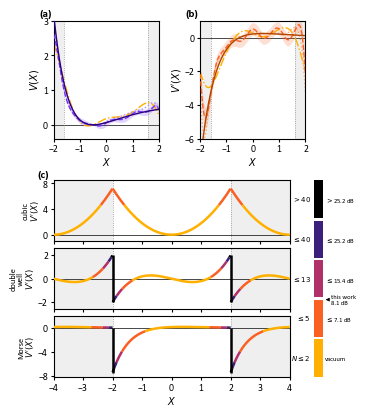

C:\Users\clara\AppData\Local\Temp\ipykernel_10396\2987957825.py:24: UserWarning: (c) is 1.74 cm wider than the space for it
  warnings.warn(f"(c) is {x0 + wc + gap + cbw + right - x1:.2f} cm wider than the space for it")


saved main_preview (7.6 x 12.9 cm)


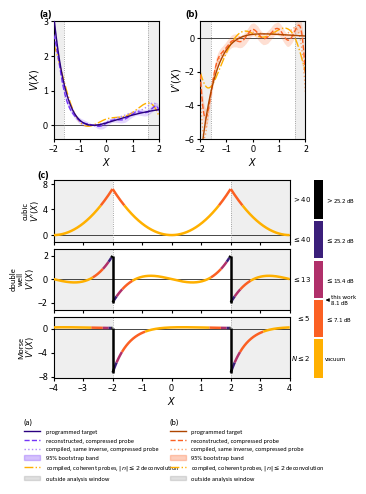

saved panel_c_bare.svg (6.97 x 5.41 cm; plotting area 6.00 cm wide)
saved panel_c_labelled.svg (9.34 x 6.26 cm; plotting area 6.00 cm wide)


In [58]:
# =====================================================================
#  MAIN-TEXT FIGURE --- (a) potential | (b) force
#                       (c) harmonics needed: cubic / double well / Morse
# =====================================================================
MAIN_W_CM = GRID_W_CM           # full column width
MAIN_TOP_H_CM = GRID_H_CM       # height of (a) and (b)
HARM_ROW_H_CM = 1.55            # height of each row of (c)
PANEL_C_W_CM = 6             # width of the plotting area of (c), in cm, set independently of
                                # (a) and (b); None fills the column. Applies to every export,
                                # bare and labelled, in the main figure and in panel_c_*.svg
HARM_ROW_GAP_CM = 0.18
HARM_CBAR_W_CM = 0.22
HARM_RIGHT_CM = {"bare": 0.3, "labelled": 1.45}    # room right of the colour bar for its labels
MAIN_GAP_CM = {"bare": 0.35, "labelled": 1.05}     # between (a,b) and (c)


def _layout_c(fig, W, Hh, x0, x1, y0, mode):
    """Three stacked rows plus a colour bar between x0 and x1 (cm), bottom at y0."""
    box = lambda x, y, ww, hh: [x / W, y / Hh, ww / W, hh / Hh]
    cbw, right = HARM_CBAR_W_CM, HARM_RIGHT_CM[mode]
    gap = 0.62 if mode == "labelled" else 0.15
    wc = x1 - x0 - right - cbw - gap if PANEL_C_W_CM is None else float(PANEL_C_W_CM)
    if PANEL_C_W_CM is not None and x0 + wc + gap + cbw + right > x1 + 1e-9:
        warnings.warn(f"(c) is {x0 + wc + gap + cbw + right - x1:.2f} cm wider than the space for it")
    rows = []
    for i in range(3):
        y = y0 + (2 - i) * (HARM_ROW_H_CM + HARM_ROW_GAP_CM)
        rows.append(fig.add_axes(box(x0, y, wc, HARM_ROW_H_CM)))
    total = 3 * HARM_ROW_H_CM + 2 * HARM_ROW_GAP_CM
    cx = x0 + wc + gap
    cax = fig.add_axes(box(cx, y0, cbw, total))            # full height of the three rows
    return rows, cax, total


def _draw_c(fig, rows, cax, text):
    for i, (ax, (lab, f, yl, st, req)) in enumerate(zip(rows, HARM)):
        draw_harmonics_row(ax, lab, f, yl, st, req, text, show_x=(i == 2))
    draw_harmonics_colorbar(fig, cax, text)


def build_main(mode):
    """mode: "bare", "labelled", or "preview" (labelled + legends for (a), (b))."""
    text = mode != "bare"
    key = "bare" if mode == "bare" else "labelled"
    P = GRID_PADS[key]
    leg = 2.6 if mode == "preview" else 0.0
    W = MAIN_W_CM
    w = (W - P["l"] - P["r"] - P["gx"]) / 2
    c_total = 3 * HARM_ROW_H_CM + 2 * HARM_ROW_GAP_CM
    Hh = leg + P["b"] + c_total + MAIN_GAP_CM[key] + MAIN_TOP_H_CM + P["t"]
    fig = plt.figure(figsize=(W * CM, Hh * CM))
    box = lambda x, y, ww, hh: [x / W, y / Hh, ww / W, hh / Hh]
    y_c = leg + P["b"]
    y_top = y_c + c_total + MAIN_GAP_CM[key]
    ax_a = fig.add_axes(box(P["l"], y_top, w, MAIN_TOP_H_CM))
    ax_b = fig.add_axes(box(P["l"] + w + P["gx"], y_top, w, MAIN_TOP_H_CM))
    draw_potential(ax_a, text); draw_force(ax_b, text)
    rows, cax, _ = _layout_c(fig, W, Hh, P["l"], W - 0.05, y_c, key)
    _draw_c(fig, rows, cax, text)
    if text:
        for letter, ax in (("(a)", ax_a), ("(b)", ax_b), ("(c)", rows[0])):
            ax.text(-0.02, 1.02, letter, transform=ax.transAxes, ha="right", va="bottom",
                    fontsize=8, fontweight="bold")
    if mode == "preview":
        for i, (title, hs) in enumerate(legend_groups()[:2]):
            fig.legend(handles=hs, title=title, title_fontsize=6, alignment="left", loc="upper left",
                       frameon=False, fontsize=4.6, handlelength=2.6,
                       bbox_to_anchor=((0.1 + i * (W - 0.2) / 2) / W, (leg - 0.1) / Hh))
    return fig


def build_panel_c(mode):
    key = "bare" if mode == "bare" else "labelled"
    P = GRID_PADS[key]
    gap = 0.62 if key == "labelled" else 0.15
    W = (MAIN_W_CM if PANEL_C_W_CM is None
         else P["l"] + float(PANEL_C_W_CM) + gap + HARM_CBAR_W_CM + HARM_RIGHT_CM[key] + 0.05)
    c_total = 3 * HARM_ROW_H_CM + 2 * HARM_ROW_GAP_CM
    Hh = P["b"] + c_total + P["t"]
    fig = plt.figure(figsize=(W * CM, Hh * CM))
    rows, cax, _ = _layout_c(fig, W, Hh, P["l"], W - 0.05, P["b"], key)
    _draw_c(fig, rows, cax, mode != "bare")
    if mode != "bare":
        rows[0].text(-0.02, 1.02, "(c)", transform=rows[0].transAxes, ha="right", va="bottom",
                     fontsize=8, fontweight="bold")
    return fig


with plt.rc_context(RC):
    for mode in ("bare", "labelled", "preview"):
        fig = build_main(mode)
        name = f"main_{mode}"
        if mode != "preview":
            fig.savefig(OUT / f"{name}.svg", format="svg", transparent=True)
        if mode == "labelled":
            fig.savefig(OUT / f"{name}.pdf", transparent=True)
        fig.savefig(OUT / f"{name}.png", dpi=300)
        print(f"saved {name} ({fig.get_figwidth() / CM:.1f} x {fig.get_figheight() / CM:.1f} cm)")
        if mode != "bare":
            plt.show()
        plt.close(fig)
    for mode in ("bare", "labelled"):
        fig = build_panel_c(mode)
        fig.savefig(OUT / f"panel_c_{mode}.svg", format="svg", transparent=True)
        print(f"saved panel_c_{mode}.svg ({fig.get_figwidth() / CM:.2f} x {fig.get_figheight() / CM:.2f} cm; "
              f"plotting area {fig.axes[0].get_position().width * fig.get_figwidth() / CM:.2f} cm wide)")
        plt.close(fig)

# the coloured curves, as CSV
pd.DataFrame({"X": _hx, **{f"{lab}_force": f(_hwrap(_hx)) for lab, f, *_ in HARM_GATES},
              **{f"{lab}_N_needed": req for lab, f, yl, st, req in HARM}}).to_csv(
    OUT / "harmonics_needed.csv", index=False)